# Scientific Interest in AMR

This notebook defines **scientific interest** (`SI`) using a **global pooled expected-count baseline** rather than directly reusing `resid_log_bg` from `5_normalisation.ipynb`.

The starting point is:

- `count` is the observed AMR-positive publication count for a given `(pathogen, antibiotic, interval)` row.
- `bg_pathogen_n` is the total publication background for the pathogen in the same interval.
- `bg_antibiotic_n` is the total publication background for the antibiotic in the same interval.
- these marginals do **not** encode resistance on their own, but they provide a sensible **background-attention baseline**.

We therefore fit the model:

`log1p(count)` = intercept + pathogen effect + antibiotic effect + effect of `log1p(bg_pathogen_n)` + effect of `log1p(bg_antibiotic_n)`

This is a **global pooled model with pathogen and antibiotic effects**.

It addresses the question:

> given only the general publication attention to this pathogen and this antibiotic, what AMR count would be typical?

We then define:

- `expected_log_count_global`: the fitted baseline expectation for `log1p(count)`
- `expected_count_global`: the same expectation mapped back to the count scale
- `SI = log1p(observed_count) - expected_log_count_global`

Under this definition:

- positive `SI` indicates more AMR publications than expected under the pooled background baseline
- negative `SI` indicates fewer AMR publications than expected

This is not asking whether the marginals can *explain resistance*. They cannot. Instead, the marginals define a **null publication baseline**, and `SI` becomes a residual or surprise score relative to that baseline.

After building the pooled baseline, we fit a LOESS smoother directly to `log1p(count)` for a single pathogen-antibiotic pair and express `SI` from that fitted count trajectory.


In [3]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from amr.scientific_interest import (
    load_amr_background_df,
    fit_global_pooled_si_model,
    plot_si_prediction,
    forecast_all_pair_si_loess,
    display_si_amr_pareto_front,
    plot_si_prediction_for_pareto_pairs,
)

## Why change the SI definition?

The earlier notebook used `resid_log_bg`, which is based on an interval-relative expected-count construction. That definition is useful for descriptive analysis, but it has an important limitation for forecasting: the expected count in one interval depends on how the full set of intervals for that pair is normalized.

For forward prediction, it is cleaner to use an expected-count model that depends only on quantities available at the same time point:

- pathogen background in that interval
- antibiotic background in that interval
- a pooled pathogen effect
- a pooled antibiotic effect

This gives a forward-looking baseline for expected AMR publication volume.

## Chosen baseline model

We use a pooled linear model on the log scale:

`log1p(count)` = `alpha` + `u_pathogen` + `v_antibiotic` + `beta_path * log1p(bg_pathogen_n)` + `beta_ab * log1p(bg_antibiotic_n)`

To make the notation concrete, suppose we are looking at publications on **_Escherichia coli_ resistance to ciprofloxacin** in one interval.

- `count` is the observed number of AMR-positive papers for that exact pair in that interval.
  In the example, this is the number of papers specifically about *E. coli* resistance to ciprofloxacin during that time window.
- `log1p(count)` is the response on the log scale.
  We use `log1p(x) = log(1 + x)` so that zero counts are handled naturally and very large counts are compressed.
- `alpha` is the global intercept.
  It represents the baseline AMR publication level before we account for which pathogen and antibiotic we are looking at, or how much general attention each of them receives.
- `u_pathogen` is the pathogen-specific effect.
  For *E. coli*, this term captures whether *E. coli* tends to attract more or fewer AMR publications than average across all antibiotics.
- `v_antibiotic` is the antibiotic-specific effect.
  For ciprofloxacin, this term captures whether ciprofloxacin tends to attract more or fewer AMR publications than average across all pathogens.
- `bg_pathogen_n` is the total publication background for the pathogen in the same interval.
  In the example, this is the total number of papers mentioning *E. coli* in that interval, regardless of whether resistance is discussed.
- `bg_antibiotic_n` is the total publication background for the antibiotic in the same interval.
  In the example, this is the total number of papers mentioning ciprofloxacin in that interval, again regardless of resistance.
- `beta_path * log1p(bg_pathogen_n)` is the contribution of general pathogen attention.
  If *E. coli* is widely studied in a given interval, this term raises the expected AMR count even before considering pair-specific resistance interest.
- `beta_ab * log1p(bg_antibiotic_n)` is the contribution of general antibiotic attention.
  If ciprofloxacin receives a great deal of overall attention in the literature, this also pushes the expected AMR count upward.

Putting this together, the model asks: if we know only that the pair is *E. coli* and ciprofloxacin, and we know how much general literature attention each receives in that interval, what AMR-positive publication count would be typical?

Interpretation:

- `u_pathogen` captures the overall AMR-publication propensity of a pathogen across antibiotics.
- `v_antibiotic` captures the overall AMR-publication propensity of an antibiotic across pathogens.
- the two log-background terms capture how general pathogen attention and general antibiotic attention scale AMR publication counts.

So in the running example, a high expected value could arise for at least three different reasons: *E. coli* is broadly important in AMR research, ciprofloxacin is broadly important in AMR research, or both receive substantial general publication attention in that interval. The model combines all of these into a single pooled baseline expectation.

## How these parameters are computed

All parameters are estimated jointly from the full interval-level dataset, not from a single pathogen-antibiotic pair in isolation.

For every row in the dataset, we assemble:

- the response `log1p(count)`
- the two continuous predictors `log1p(bg_pathogen_n)` and `log1p(bg_antibiotic_n)`
- an indicator for the pathogen identity
- an indicator for the antibiotic identity

So if the row corresponds to *E. coli* and ciprofloxacin, the design vector contains the two log-background values for that interval, a 1 in the *E. coli* pathogen column, a 1 in the ciprofloxacin antibiotic column, and 0 in the other pathogen and antibiotic columns.

The model is then fitted across all rows at once using **ridge regression** on the log scale. In practice, this means:

- `alpha` is the fitted intercept of the regression model
- `beta_path` is the fitted coefficient multiplying `log1p(bg_pathogen_n)`
- `beta_ab` is the fitted coefficient multiplying `log1p(bg_antibiotic_n)`
- each `u_pathogen` value comes from the fitted coefficient of that pathogen's one-hot indicator
- each `v_antibiotic` value comes from the fitted coefficient of that antibiotic's one-hot indicator

The ridge penalty shrinks coefficients toward zero, which helps stabilize the fit when many pathogens and antibiotics are represented and some pairs are sparse.

In the code, this is implemented by building a design matrix with:

- two numeric columns: `log_bg_pathogen_n` and `log_bg_antibiotic_n`
- one-hot columns for all pathogens
- one-hot columns for all antibiotics

and fitting a `Ridge` model to predict `log_count`.

After fitting, the model produces a predicted value for every row:

`expected_log_count_global = alpha + u_pathogen + v_antibiotic + beta_path * log1p(bg_pathogen_n) + beta_ab * log1p(bg_antibiotic_n)`

For the running example, the expected log-count for *E. coli* and ciprofloxacin in a given interval is obtained by plugging in:

- the fitted global intercept
- the fitted *E. coli* coefficient
- the fitted ciprofloxacin coefficient
- the observed `bg_pathogen_n` for *E. coli* in that interval
- the observed `bg_antibiotic_n` for ciprofloxacin in that interval

That gives the pooled baseline for what AMR publication volume would be expected before looking at whether this specific pair is unusually over- or under-studied.

## New SI definition

Once the baseline is fitted, the scientific-interest score becomes:

`SI = log1p(count) - expected_log_count_global`

This is the observed `SI`. For smoothing and extrapolation, we do not fit `SI` directly. Instead, we fit a LOESS smoother to `log1p(count)` for the selected pair and derive fitted or predicted `SI` from that count fit:

`predicted_SI = predicted_log_count_loess - expected_log_count_global`

## Why fit counts first

This keeps the workflow aligned with the scientific question:

- first estimate a smooth trajectory for AMR publication counts
- then measure scientific interest as the gap between that smooth count trajectory and the pooled background expectation

The model is therefore easier to interpret: the orange curve is the fitted count trajectory, and the red curve is simply the `SI` implied by that orange curve.

## Practical limitation

This notebook still works with interval-level data rather than yearly pair-level data. As a result, the LOESS curve is fitted to interval end-years such as `1979, 1984, ..., 2024`, and then evaluated on a yearly grid for visualization. The observed points remain interval-level observations.


In [4]:
amr_bg_df = load_amr_background_df()
si_df, pooled_model, pooled_feature_columns = fit_global_pooled_si_model(amr_bg_df, alpha=1.0)

display(
    si_df[
        [
            "pathogen",
            "antibiotic",
            "start_year",
            "end_year",
            "count",
            "bg_pathogen_n",
            "bg_antibiotic_n",
            "expected_count_global",
            "SI",
        ]
    ].head()
)

,pathogen,antibiotic,start_year,end_year,count,bg_pathogen_n,bg_antibiotic_n,expected_count_global,SI
0,Abiotrophia defectiva,Cefepime,2015,2019,1,45,1075,0.794418,0.108466
1,Abiotrophia defectiva,Cefotaxime,2015,2019,1,45,1510,1.116866,-0.056789
2,Abiotrophia defectiva,Ceftriaxone,2010,2014,1,24,2233,0.752940,0.131853
3,Abiotrophia defectiva,Ciprofloxacin,2010,2014,1,24,5755,1.474945,-0.213071
4,Abiotrophia defectiva,Clindamycin,2000,2004,1,20,1076,0.760674,0.127450


## Inspect the pooled baseline

After fitting the pooled model, a few quantities are especially worth checking:

- `expected_count_global`: the background-only expected AMR count
- `SI`: the residual or surprise score on the log scale
- the coefficients on `log_bg_pathogen_n` and `log_bg_antibiotic_n`

There are many one-hot effects, so the notebook does not print all of them by default. The two continuous coefficients are often the most informative, because they show how strongly expected AMR volume scales with general pathogen attention and general antibiotic attention.


In [5]:
coef_df = pd.DataFrame(
    {
        "feature": pooled_feature_columns,
        "coefficient": pooled_model.coef_,
    }
)

display(coef_df[coef_df["feature"].isin(["log_bg_pathogen_n", "log_bg_antibiotic_n"])])

print("Model intercept:", float(pooled_model.intercept_))

,feature,coefficient
0,log_bg_pathogen_n,0.165228
1,log_bg_antibiotic_n,0.185721


Model intercept: -1.4143686872619263


## LOESS fit on log-counts

Earlier versions of the notebook tried to forecast AMR counts with several GP-based decompositions. In practice, that approach proved too fragile for these interval data: each pair has only a small number of 5-year observations, so the extra layers were difficult to identify, and the orange curve often reflected model assumptions more than signal.

This version uses a simpler approach.

For a single pathogen-antibiotic pair, we:

1. keep the pooled global baseline `expected_log_count_global`
2. fit a LOESS smoother directly to the observed pair trajectory `log1p(count)` over time
3. use that fitted log-count trajectory as the smooth estimate of future AMR count
4. define fitted or predicted `SI` from counts as:
   `predicted_SI = predicted_log_count_loess - expected_log_count_baseline`

The red curve is therefore the `SI` implied by the LOESS fit on log-counts.

### Why this is simpler

The LOESS model is intentionally modest. It does not try to separate trend, residual GPs, future background models, or multiple interacting layers of uncertainty. It only asks:

`What smooth log-count trajectory best matches this pair in the chosen fit window?`

Once that trajectory is estimated, we compare it with the pooled background expectation. The difference is the fitted `SI`.

### What the uncertainty band means now

The `±1 std` band is based on the residual spread of the training log-counts around the LOESS fit. It is therefore a simple empirical band rather than a formal predictive interval.

### Practical interpretation

- orange line: LOESS fit of `log1p(count)`, converted back to counts
- red line: `SI` implied by that LOESS count fit relative to the pooled baseline
- navy line: observed `SI`
- bars: observed per-interval AMR count and the two marginals on the secondary axis

This keeps the model aligned with the user-facing question: first smooth the counts, then express scientific interest from the smoothed counts.


In [6]:
# Analysis helpers live in `amr.scientific_interest`.
# The notebook stays focused on inspection and experiments.


## Example

The example below fits a LOESS smoother directly to `log1p(count)` for one pair, converts that smooth count trajectory back to counts, and then expresses `SI` as the gap between the fitted log-count and the pooled global baseline.

The interpretation is therefore:

- first smooth the AMR counts on the log scale
- then derive `SI` from those fitted counts

This keeps the workflow simple and makes the red `SI` curve a direct consequence of the orange count fit.

`loess_frac` is the smoothing span for the LOESS fit. It controls how much of the data each local regression uses. A larger `loess_frac` produces a smoother, less reactive curve, while a smaller `loess_frac` lets the fit follow shorter-term rises and falls more closely.


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:216: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 7'). Falling back to linear LOESS.
  warnings.warn(


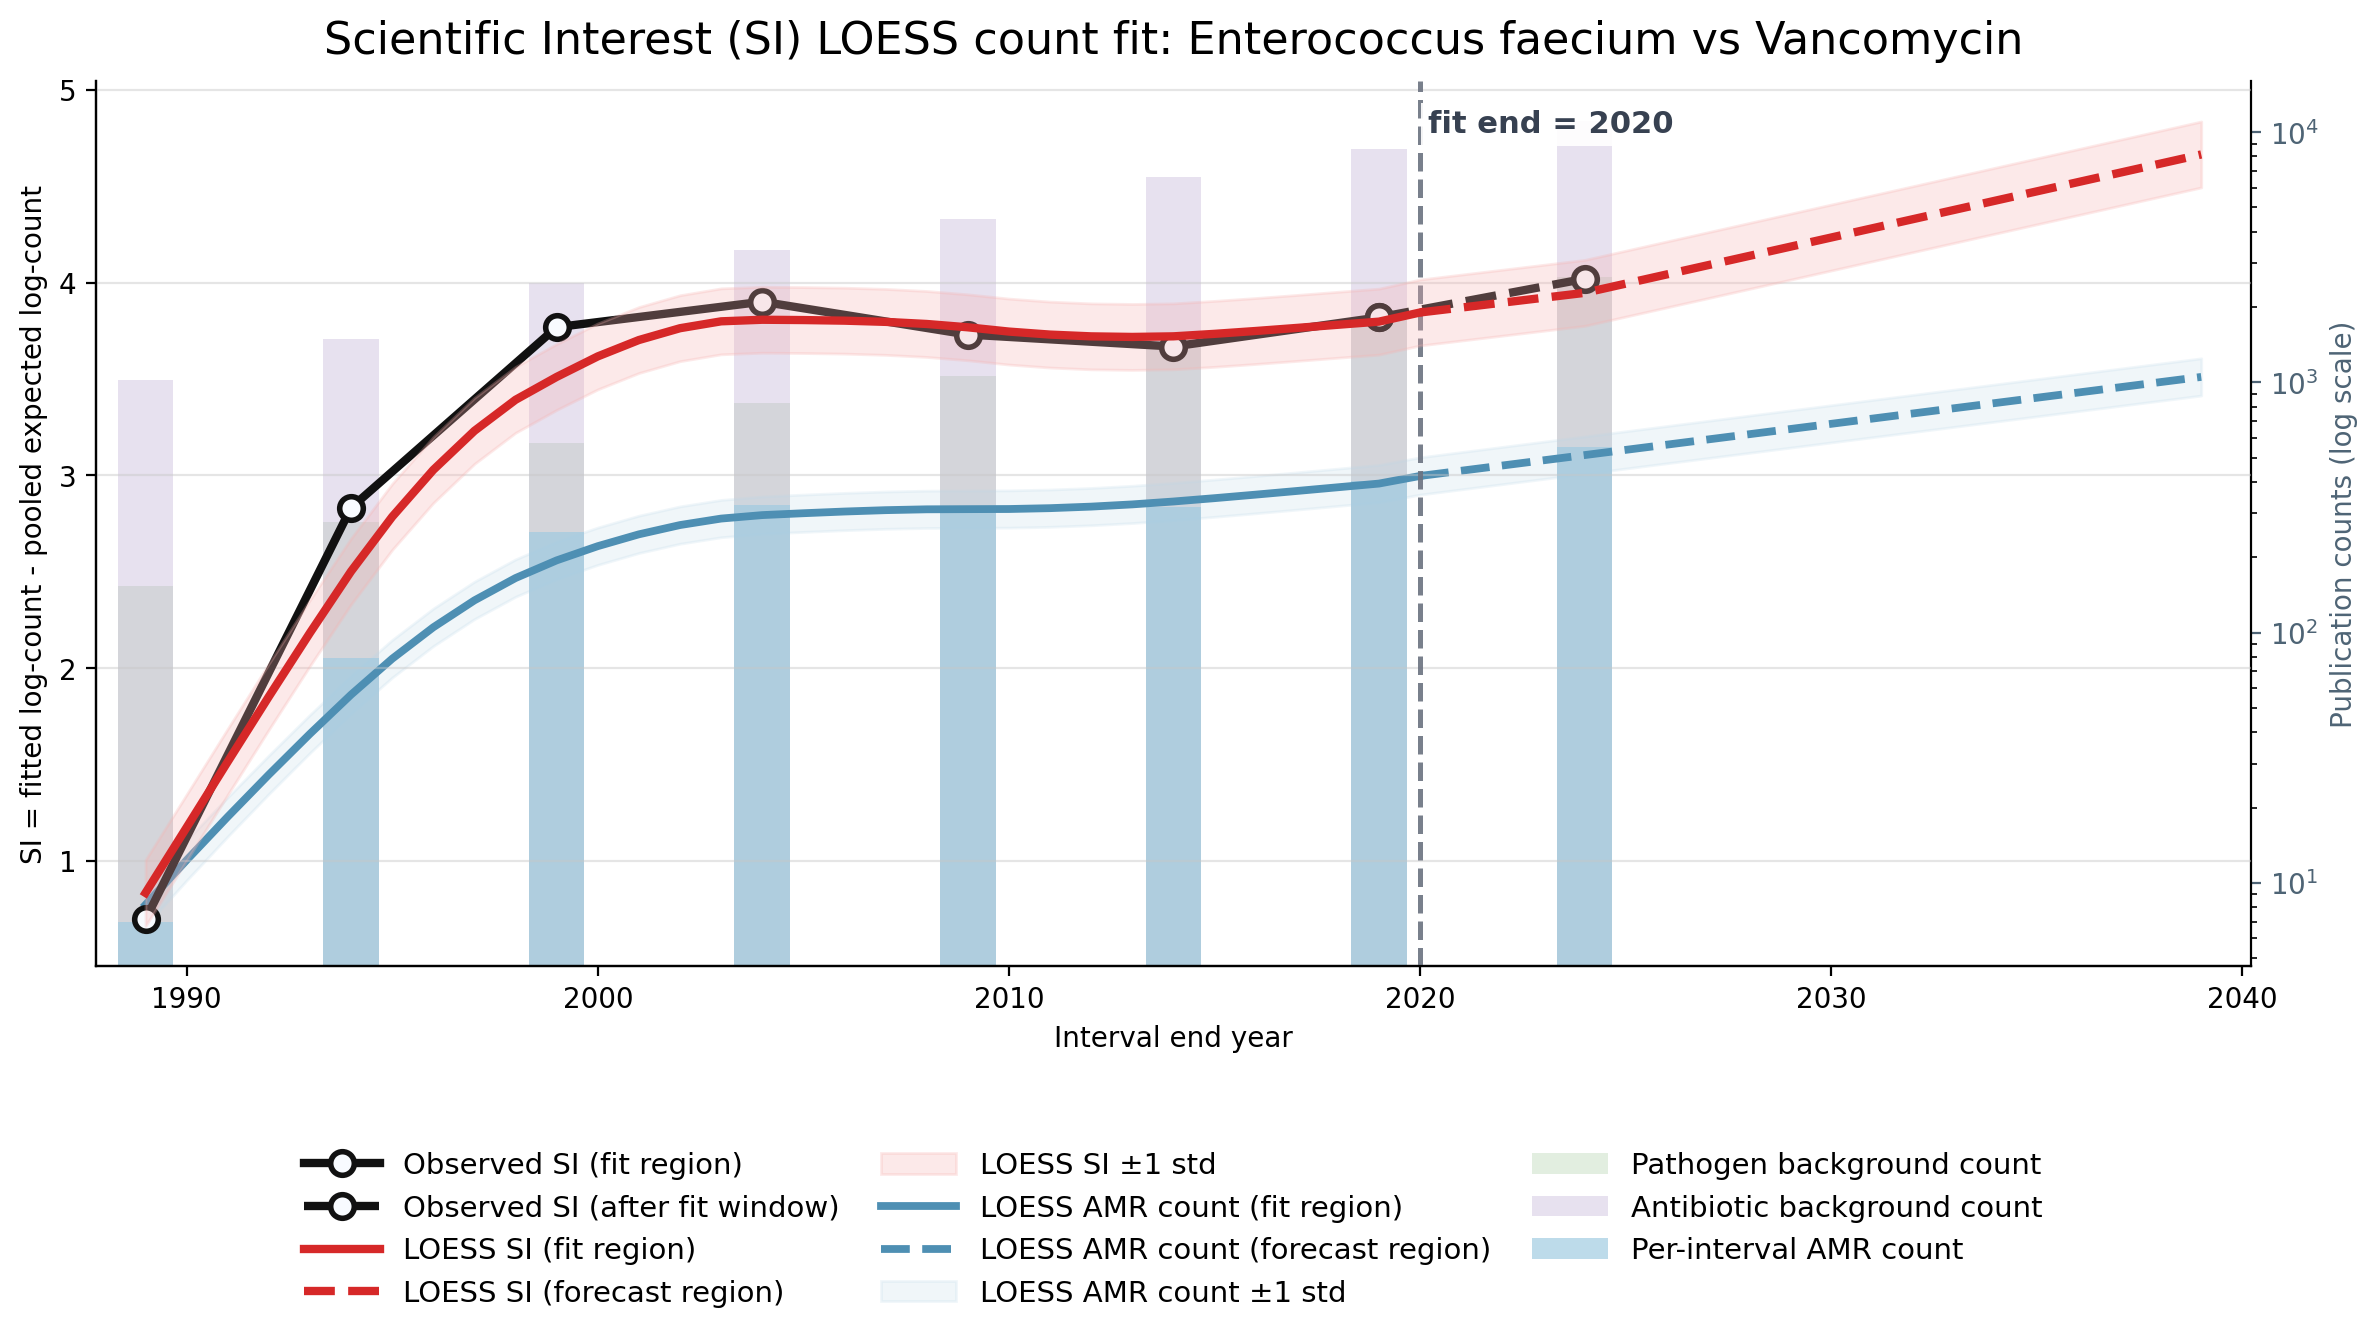

,year,observed_SI,observed_count,observed_log_count,expected_count_global,expected_log_count_global,expected_log_count_baseline,expected_count_baseline,predicted_log_count_loess,predicted_log_count_std,...,predicted_count_loess_upper_1std,predicted_SI,predicted_std,lower_1std,upper_1std,prediction_error,abs_error,within_1std,count_prediction_error_loess,count_abs_error_loess
0,1989,0.696450,7,2.079442,2.986812,1.382992,1.382992,2.986812,2.217326,0.170995,...,9.895191,0.834334,0.170995,0.663339,1.005330,-0.137885,0.137885,True,-1.182744,1.182744
1,1994,2.832146,79,4.382027,3.710909,1.549881,1.549881,3.710909,4.052420,0.170995,...,67.266219,2.502539,0.170995,2.331543,2.673534,0.329607,0.329607,False,22.463496,22.463496
2,1999,3.768860,252,5.533389,4.838824,1.764529,1.764529,4.838824,5.275445,0.170995,...,230.931025,3.510915,0.170995,3.339920,3.681911,0.257945,0.257945,False,57.522640,57.522640
3,2004,3.901081,324,5.783825,5.571516,1.882745,1.882745,5.571516,5.690159,0.170995,...,350.129105,3.807414,0.170995,3.636419,3.978409,0.093667,0.093667,True,29.059470,29.059470
4,2009,3.730550,300,5.707110,6.217875,1.976561,1.976561,6.217875,5.744805,0.170995,...,369.850949,3.768244,0.170995,3.597249,3.939240,-0.037695,0.037695,True,-11.562601,11.562601
5,2014,3.668559,317,5.762051,7.113197,2.093492,2.093492,7.113197,5.814853,0.170995,...,396.760038,3.721361,0.170995,3.550366,3.892357,-0.052802,0.052802,True,-17.242265,17.242265
6,2019,3.819691,403,6.001415,7.861570,2.181724,2.181724,7.861570,5.979326,0.170995,...,467.868172,3.797602,0.170995,3.626607,3.968598,0.022089,0.022089,True,8.825993,8.825993
7,2024,4.019537,551,6.313548,8.914631,2.294012,2.294012,8.914631,6.240778,0.170995,...,607.972936,3.946767,0.170995,3.775771,4.117762,0.072770,0.072770,True,38.742138,38.742138


LOESS fraction: 0.7
LOESS degree: 1
Training residual std on log-count scale: 0.17099545430505905
Latest observed interval end year: 2024


In [15]:
result = plot_si_prediction(
    si_df=si_df,
    antibiotic="Vancomycin",
    pathogen="Enterococcus faecium",
    fit_start_year=1970,
    fit_end_year=2020,
    num_additional_years=15,
    loess_frac=0.7,
    loess_degree=2,
)

display(result["comparison_df"])
print("LOESS fraction:", result["loess_fit"]["frac"])
print("LOESS degree:", result["loess_fit"]["degree"])
print("Training residual std on log-count scale:", result["loess_fit"]["residual_std"])
print("Latest observed interval end year:", result["latest_available_year"])


,pareto_shell,pathogen,antibiotic,mean_SI,mean_count,total_count,n_intervals,latest_interval_end
0,1,Enterococcus faecium,Vancomycin,3.304609,279.125,2233,8,2024
1,1,Escherichia coli,Ampicillin,2.514602,326.600,3266,10,2024
2,2,Helicobacter pylori,Clarithromycin,3.033257,248.000,1736,7,2024
3,2,Escherichia coli,Ciprofloxacin,1.928766,277.125,2217,8,2024
4,3,Helicobacter pylori,Metronidazole,2.867025,166.500,1332,8,2024
5,3,Mycobacterium tuberculosis,Rifampicin,2.553699,215.600,2156,10,2024
6,3,Escherichia coli,Tetracycline,2.104933,216.900,2169,10,2024
7,4,Enterococcus faecalis,Vancomycin,2.596327,124.750,998,8,2024
8,4,Acinetobacter baumannii,Colistin,2.308377,149.750,599,4,2024
9,4,Staphylococcus aureus,Oxacillin,2.296807,163.400,1634,10,2024


Plotting Enterococcus faecium vs Vancomycin


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 7'). Falling back to linear LOESS.
  warnings.warn(


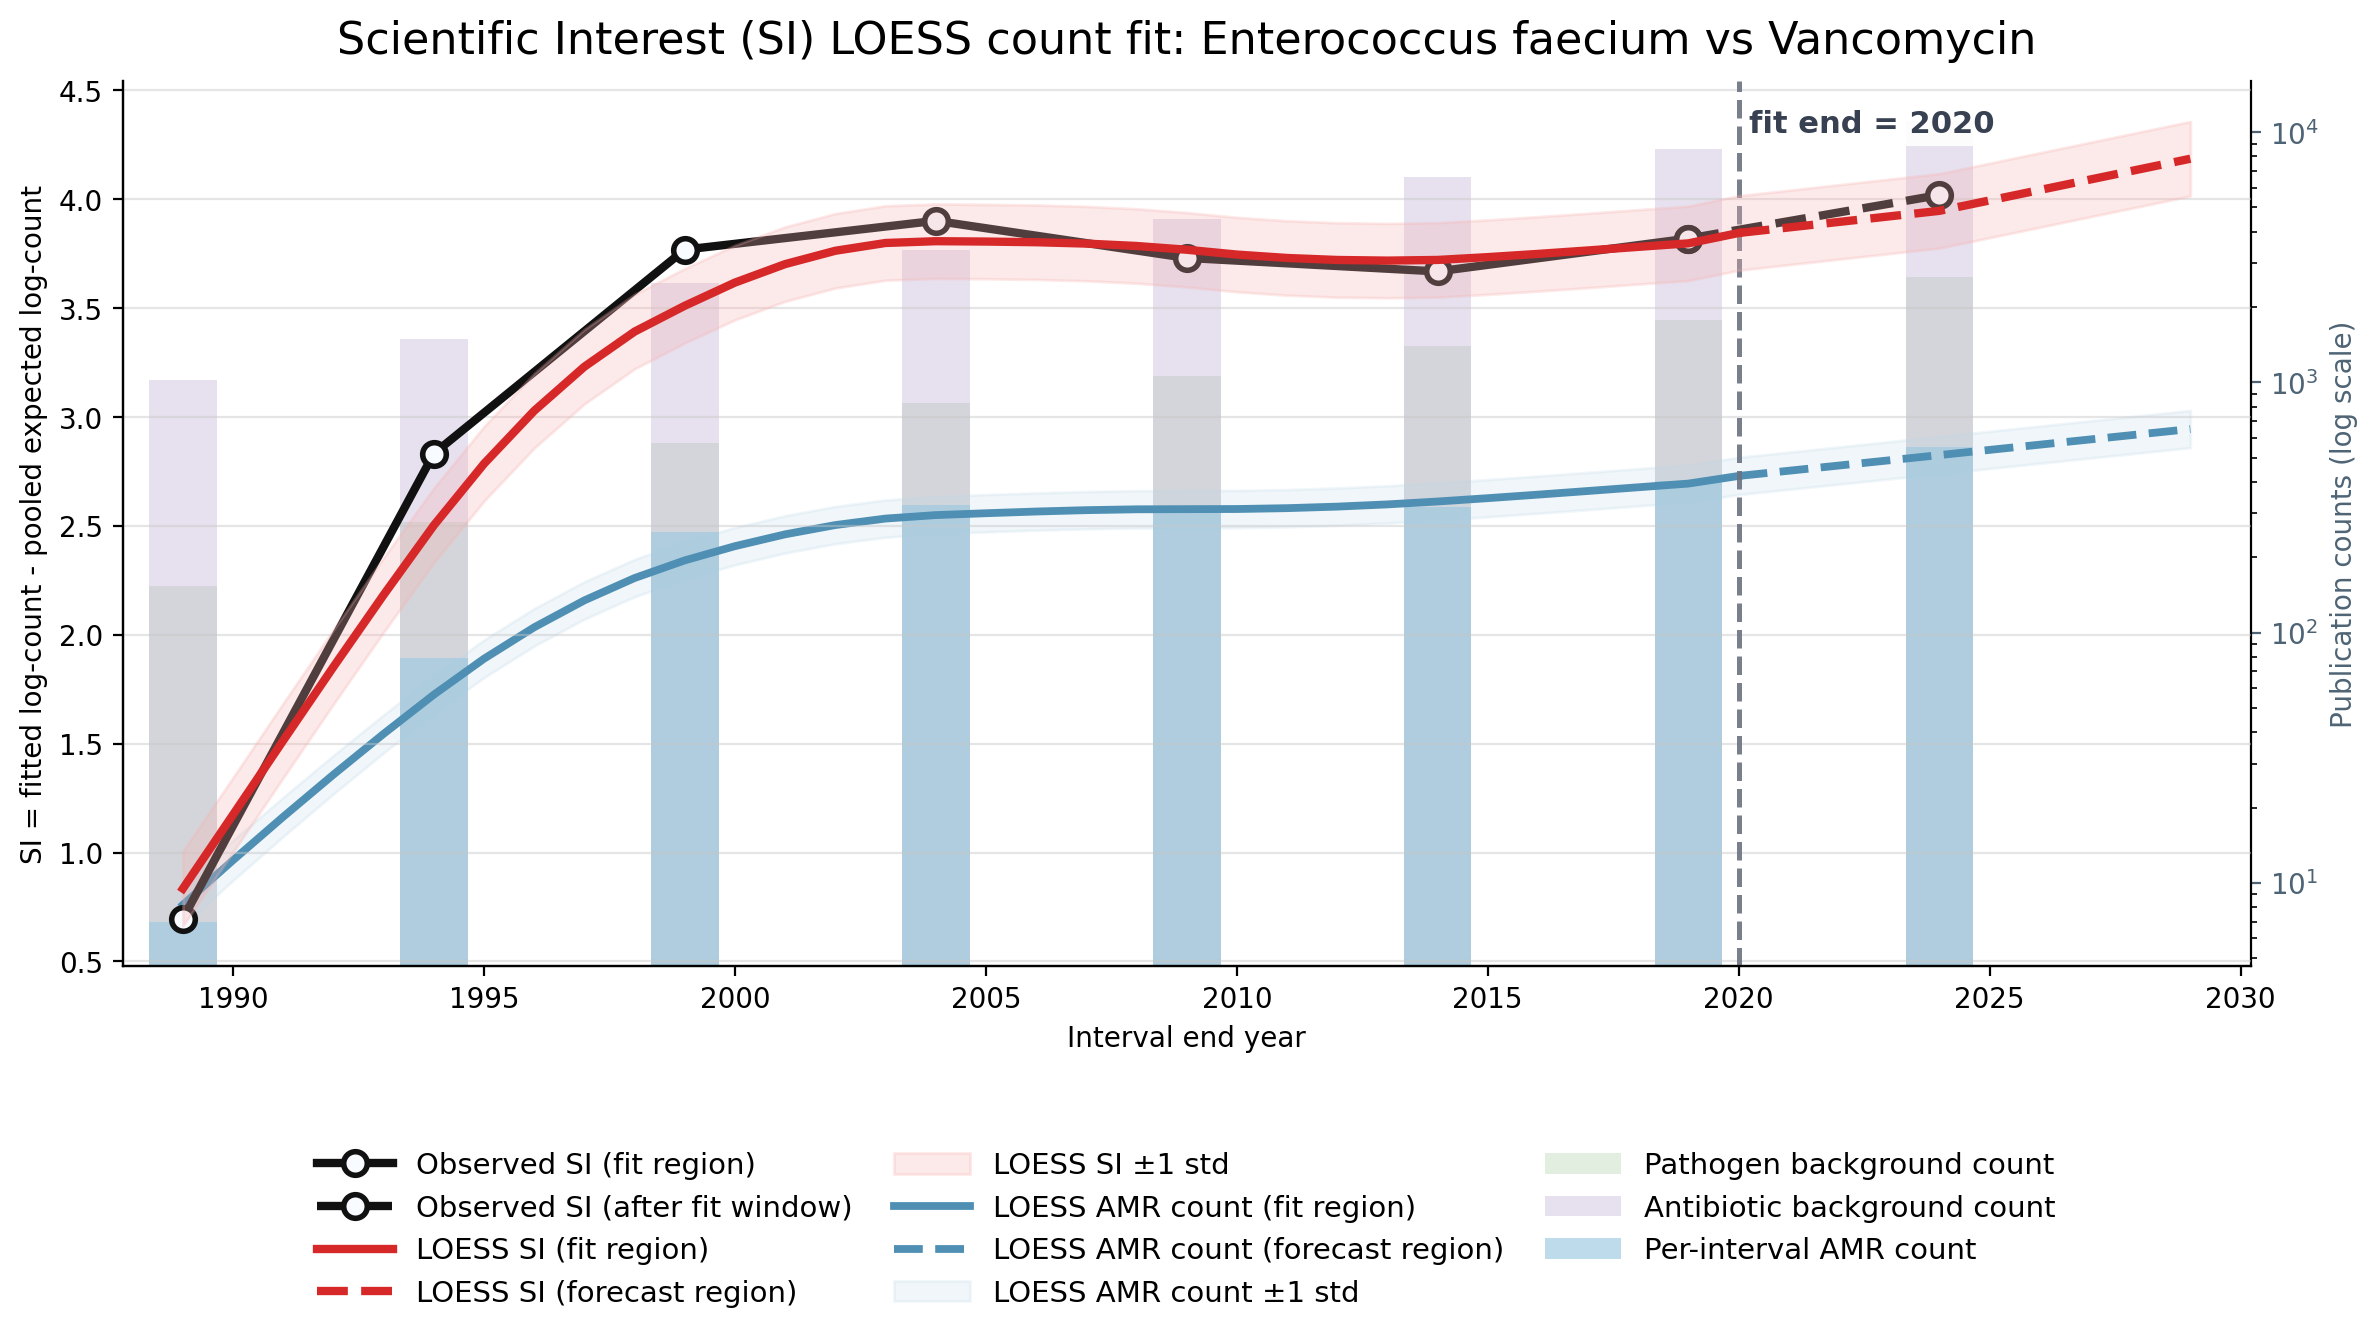

Plotting Escherichia coli vs Ampicillin


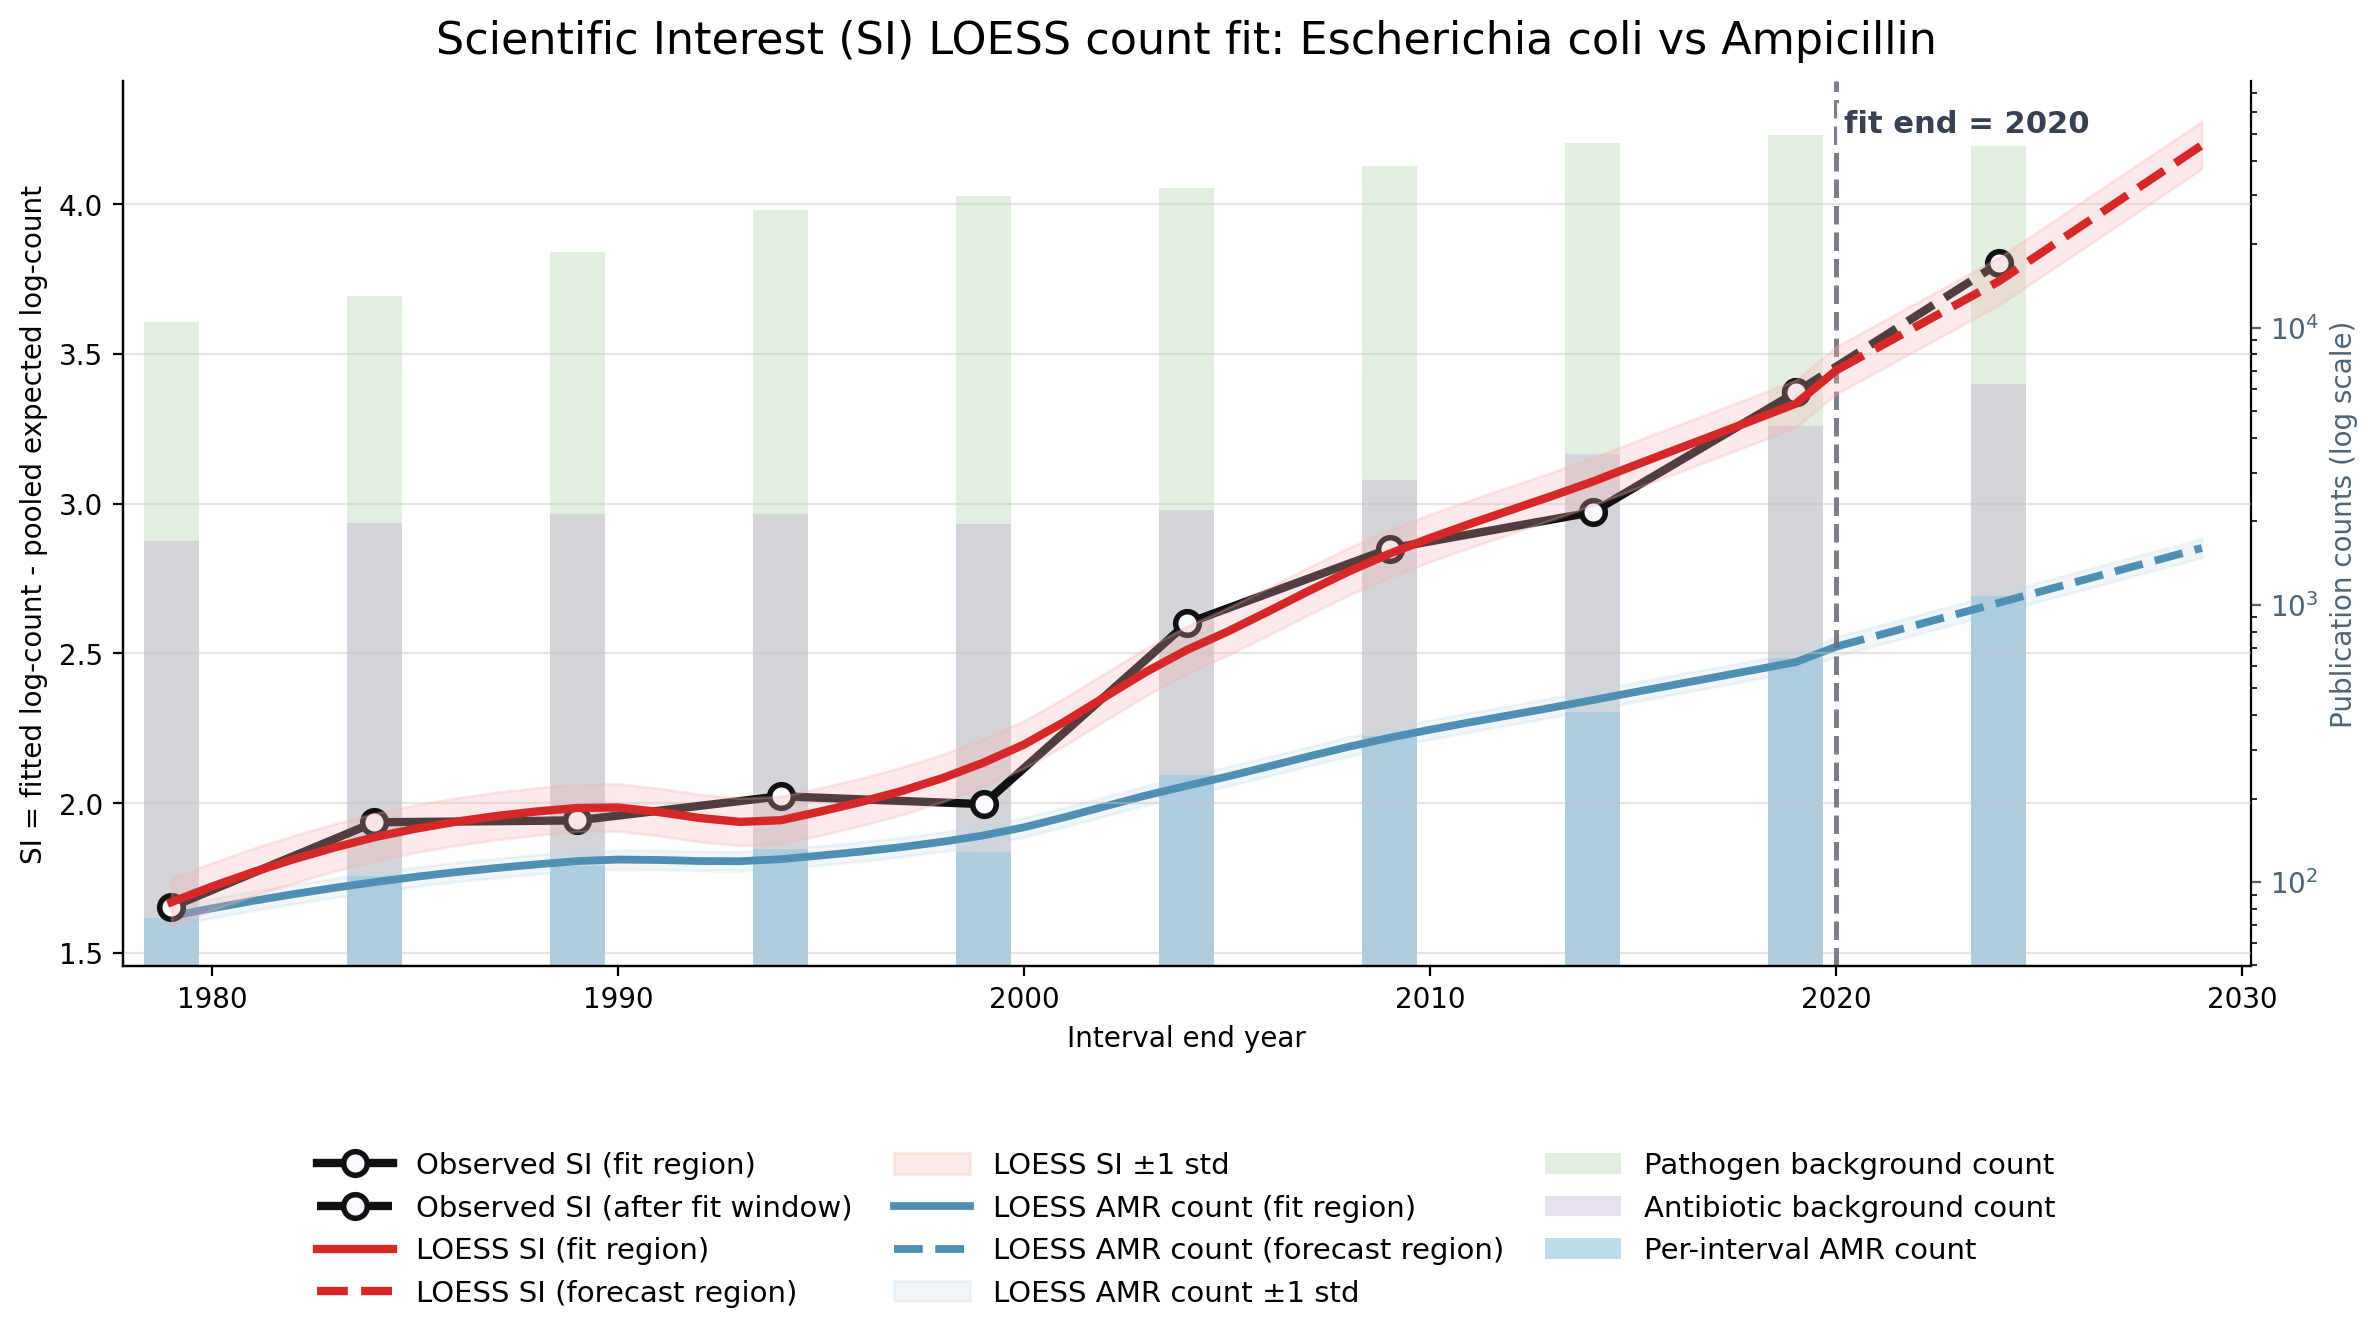

Plotting Helicobacter pylori vs Clarithromycin


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 6'). Falling back to linear LOESS.
  warnings.warn(


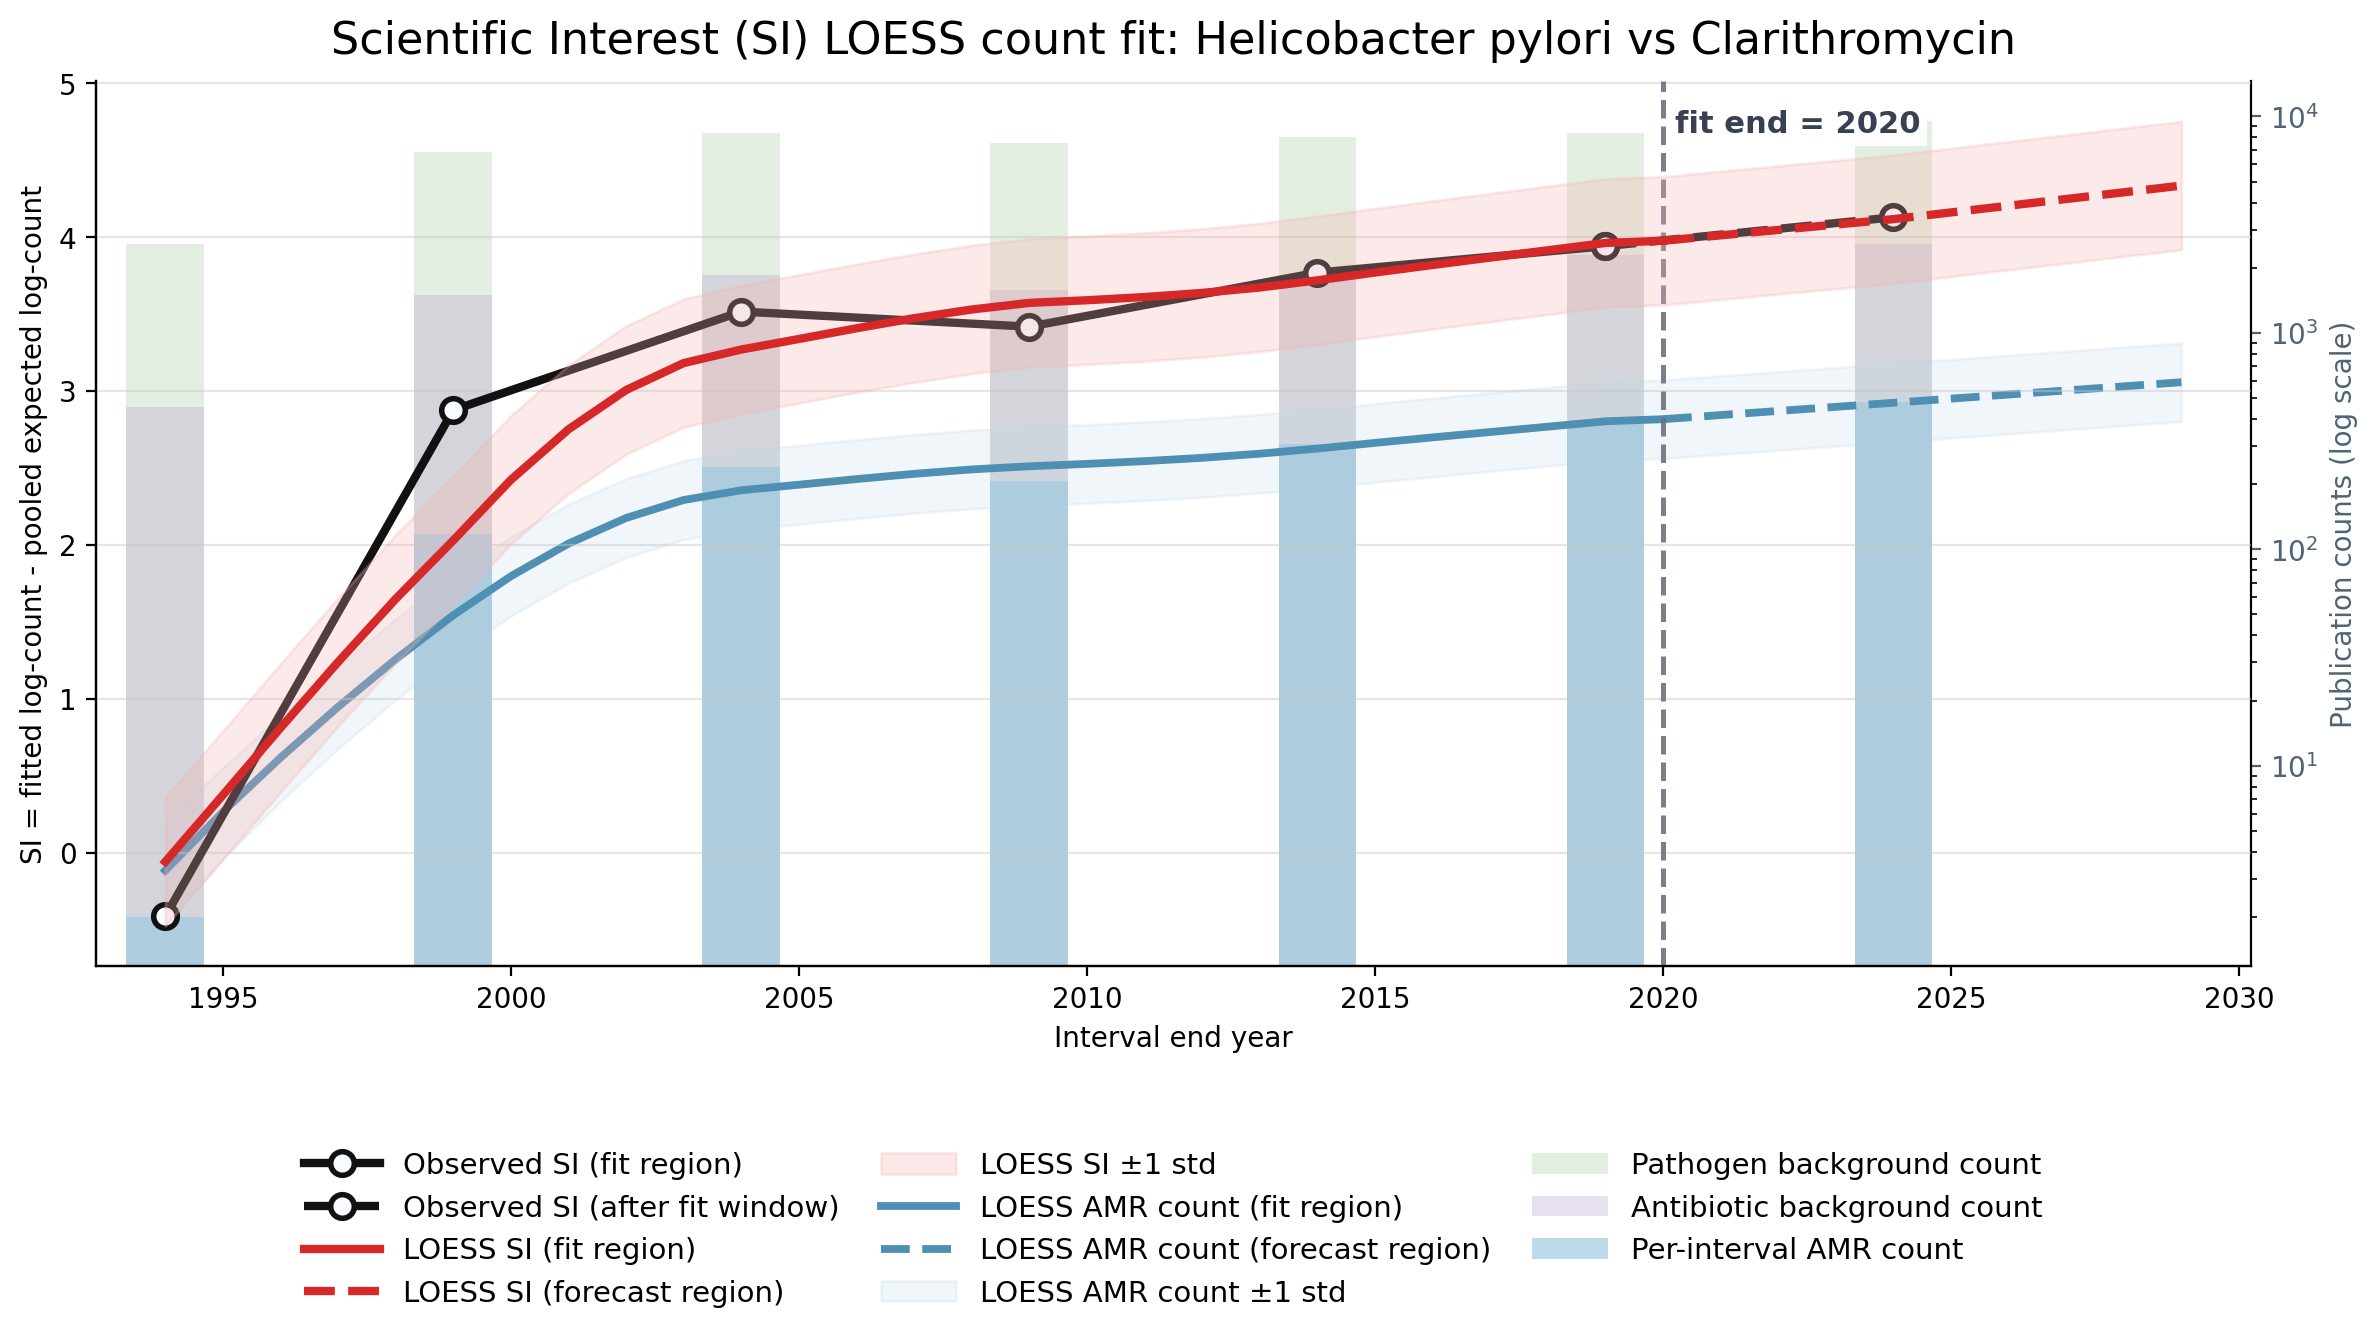

Plotting Escherichia coli vs Ciprofloxacin


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 7'). Falling back to linear LOESS.
  warnings.warn(


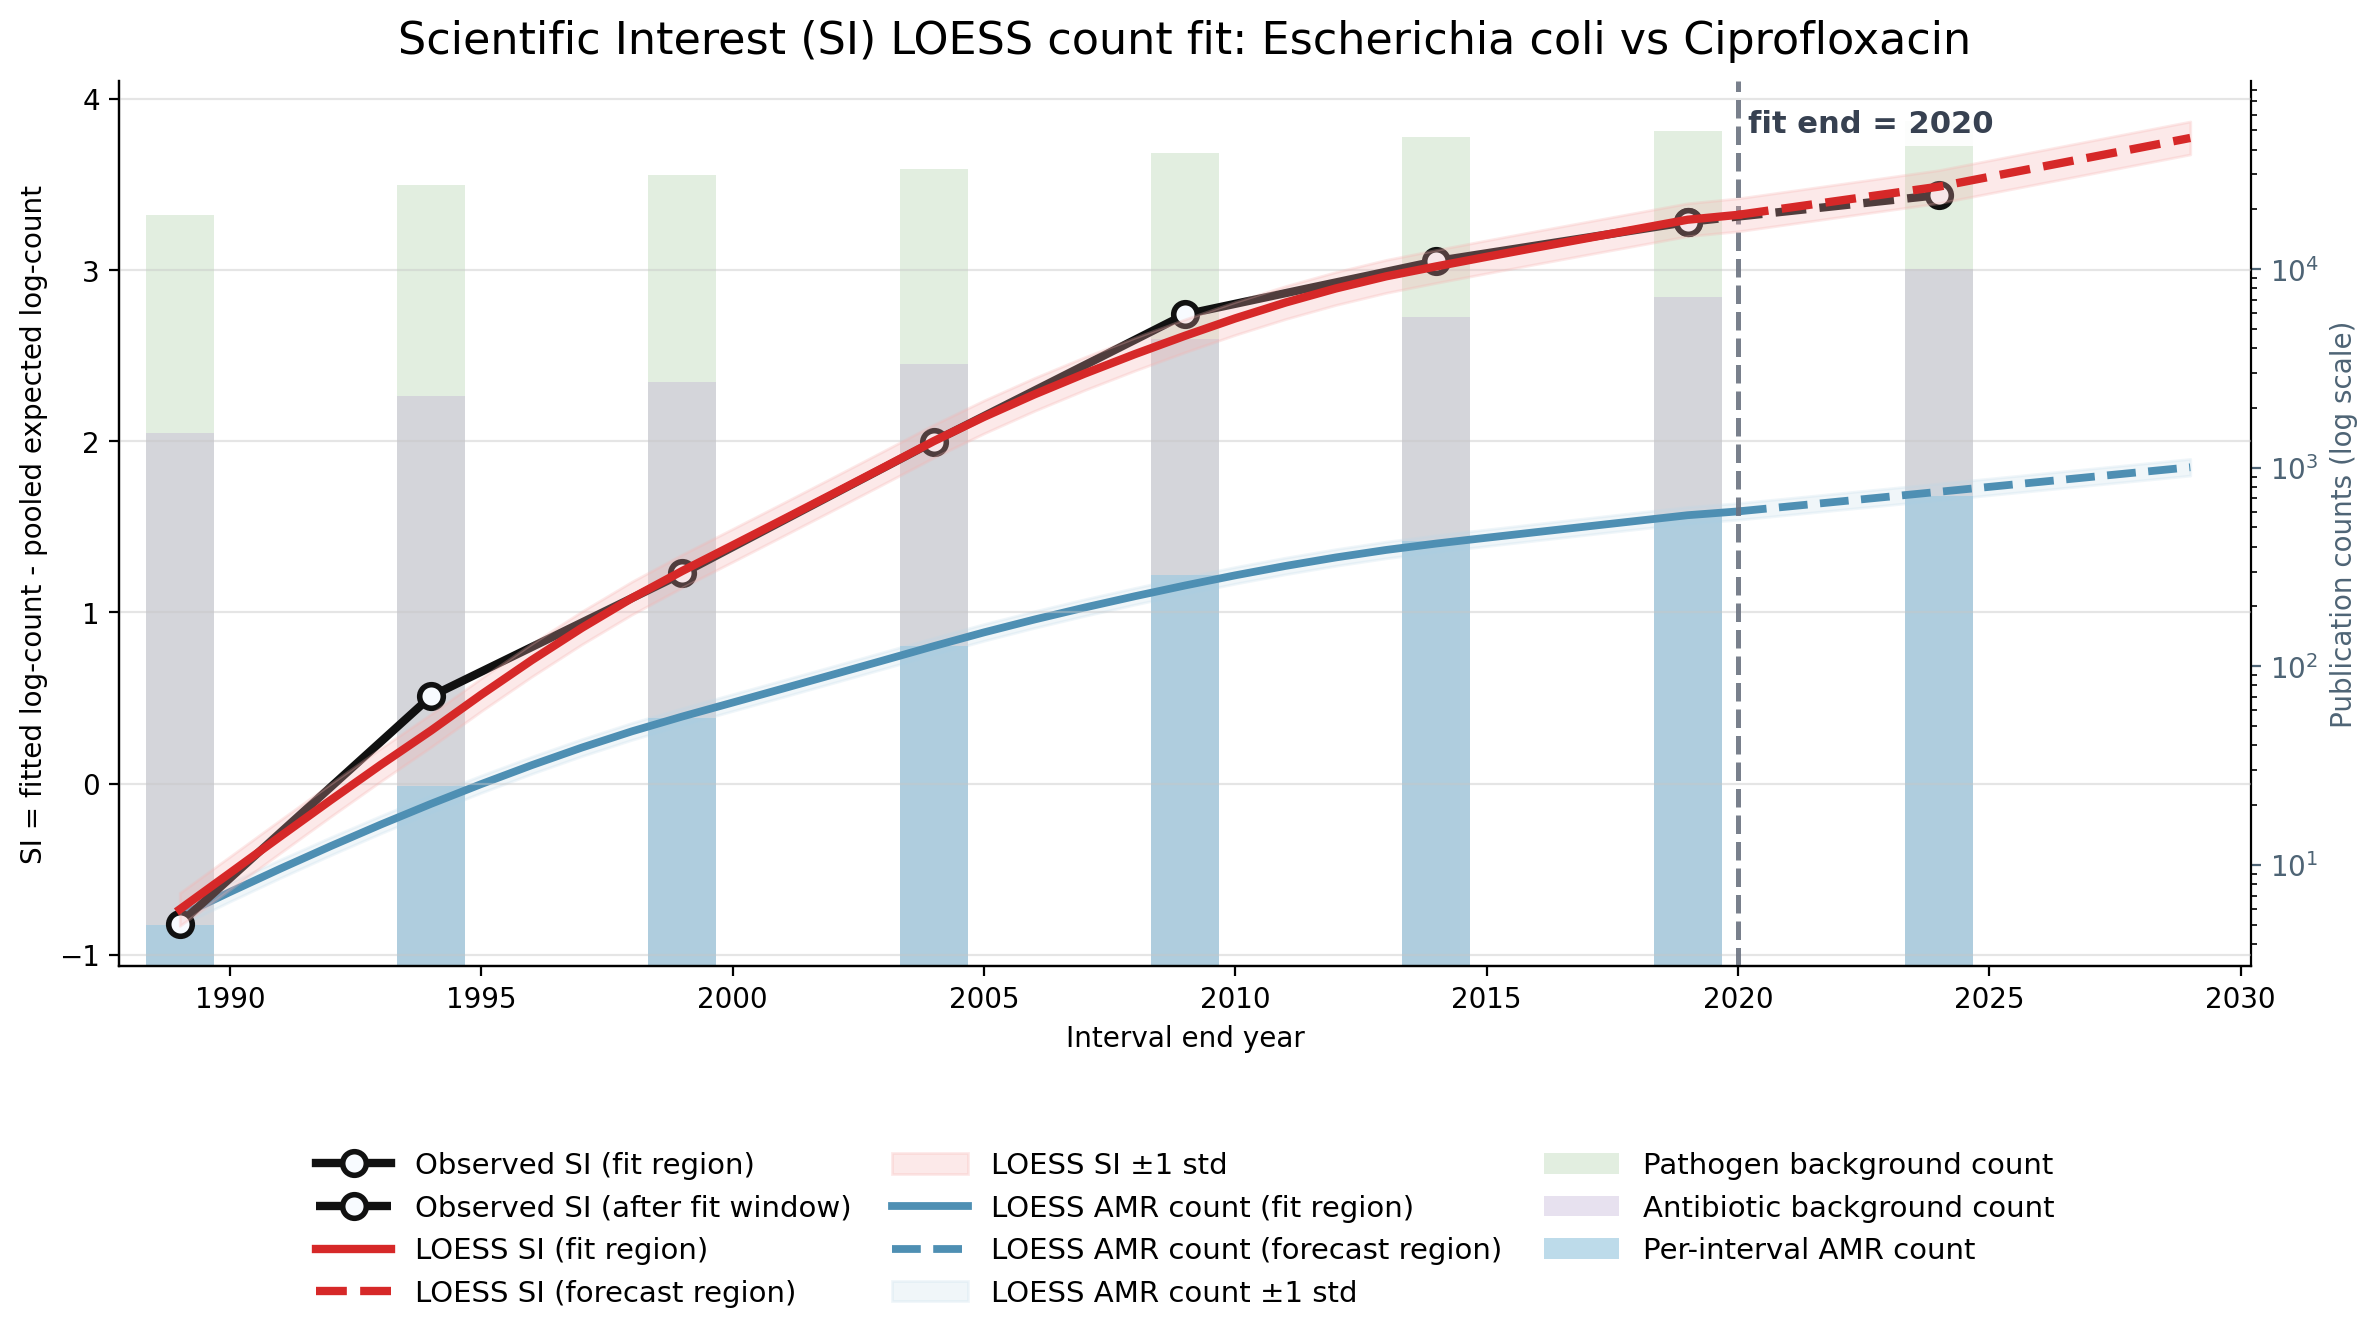

Plotting Helicobacter pylori vs Metronidazole


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 7'). Falling back to linear LOESS.
  warnings.warn(


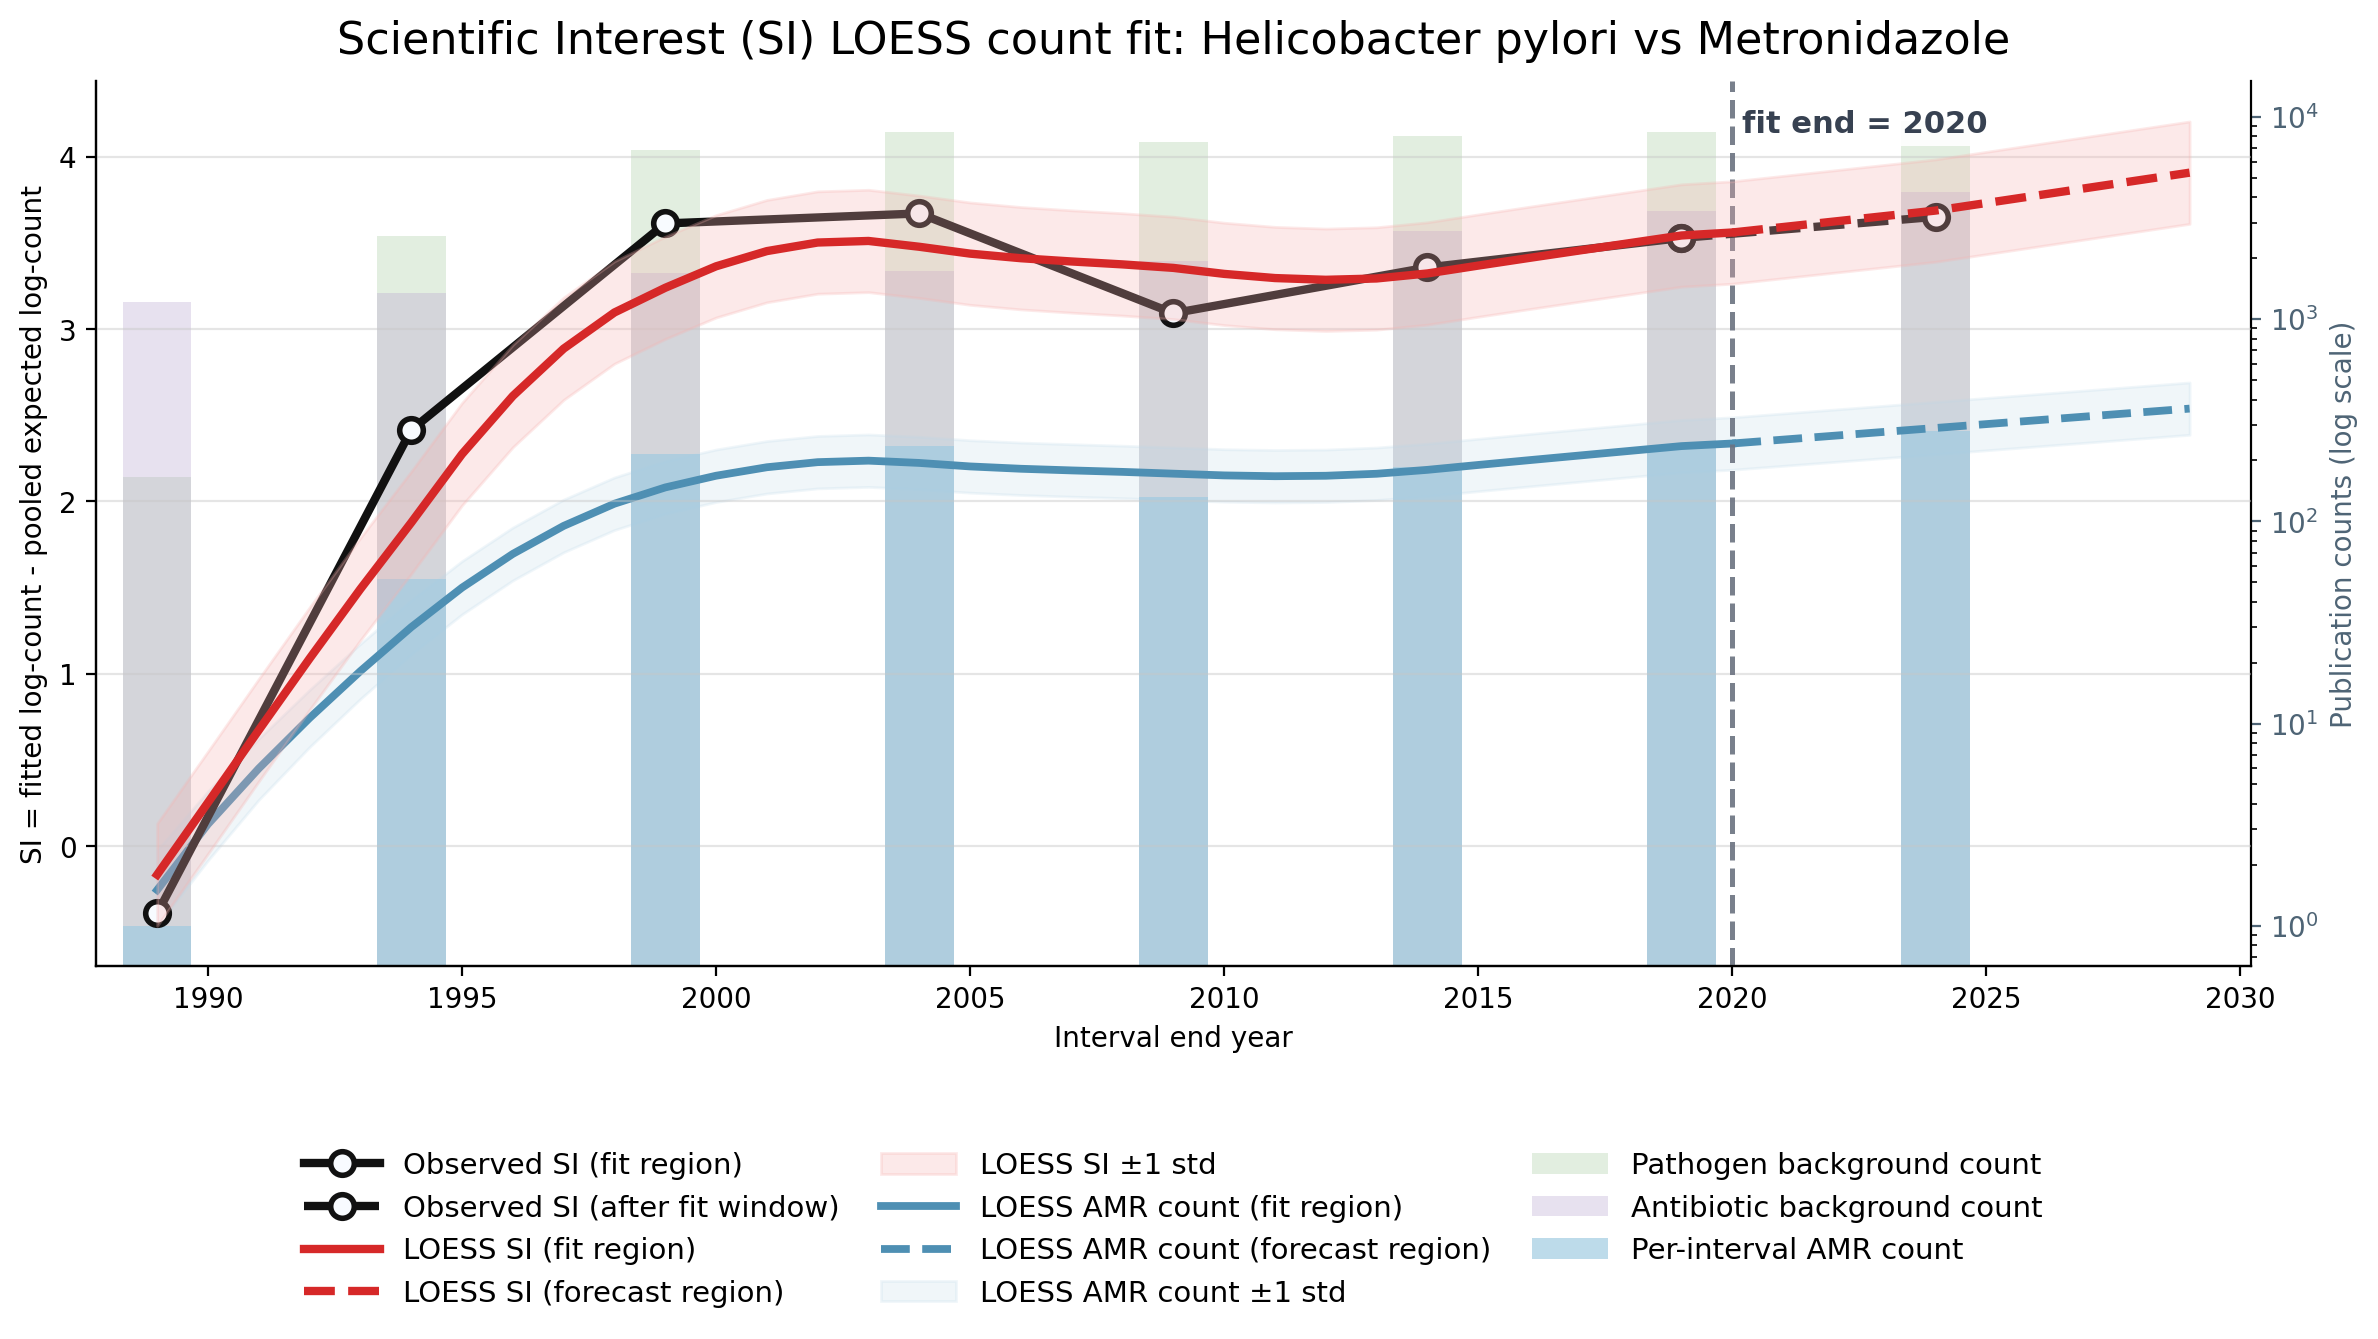

Plotting Mycobacterium tuberculosis vs Rifampicin


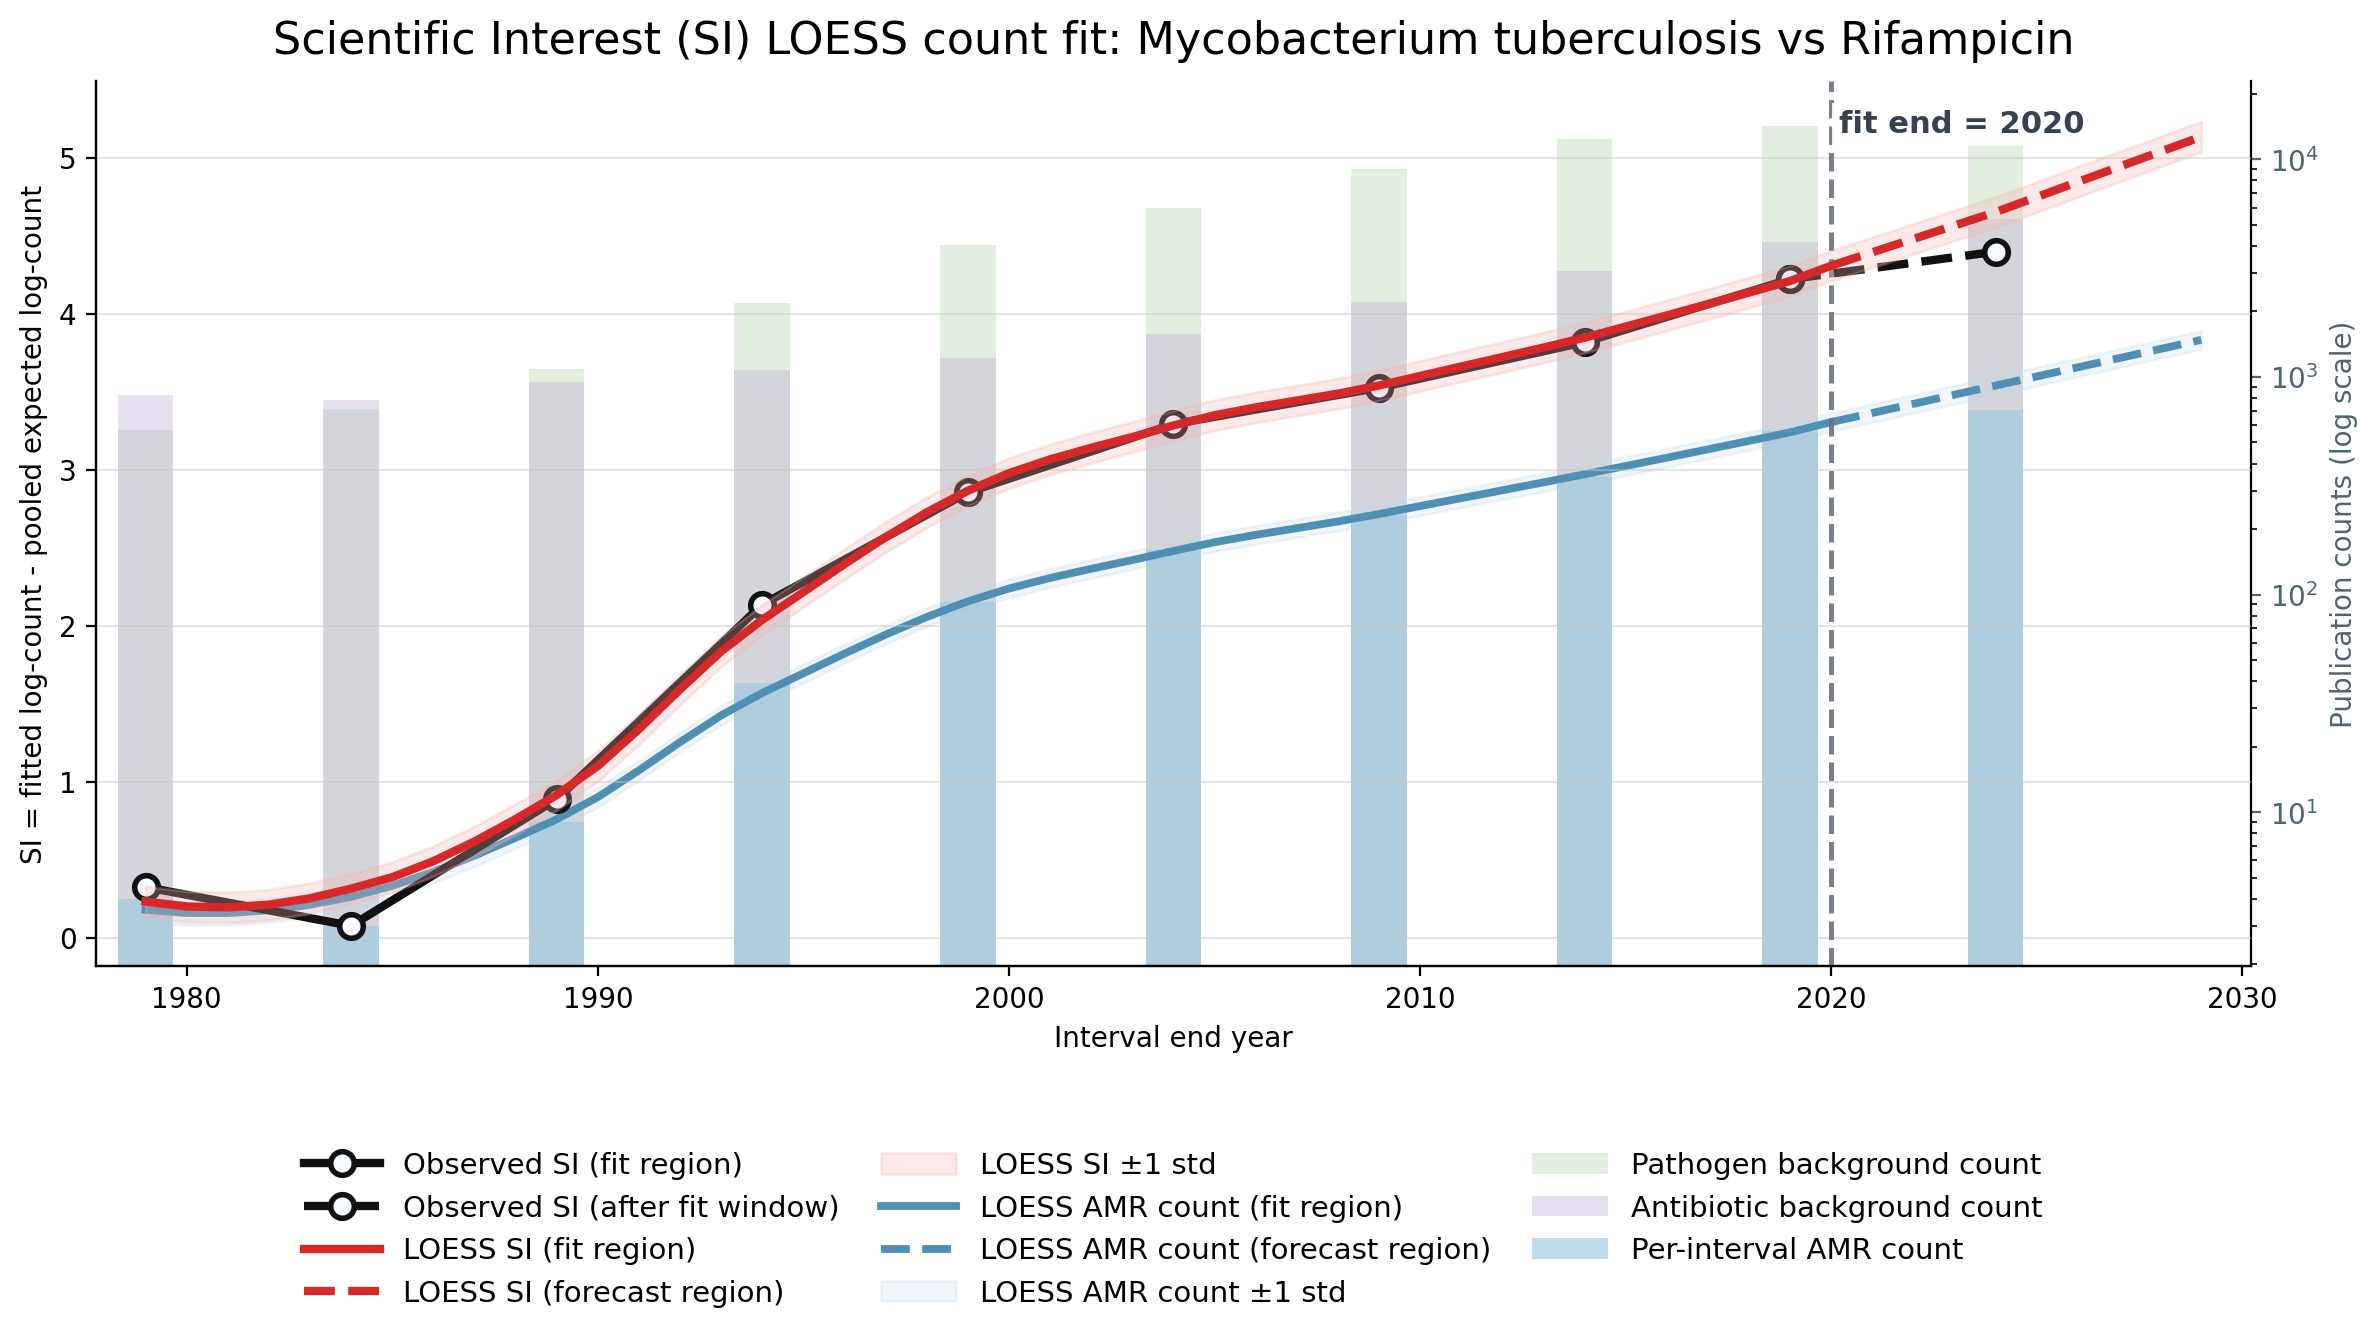

Plotting Escherichia coli vs Tetracycline


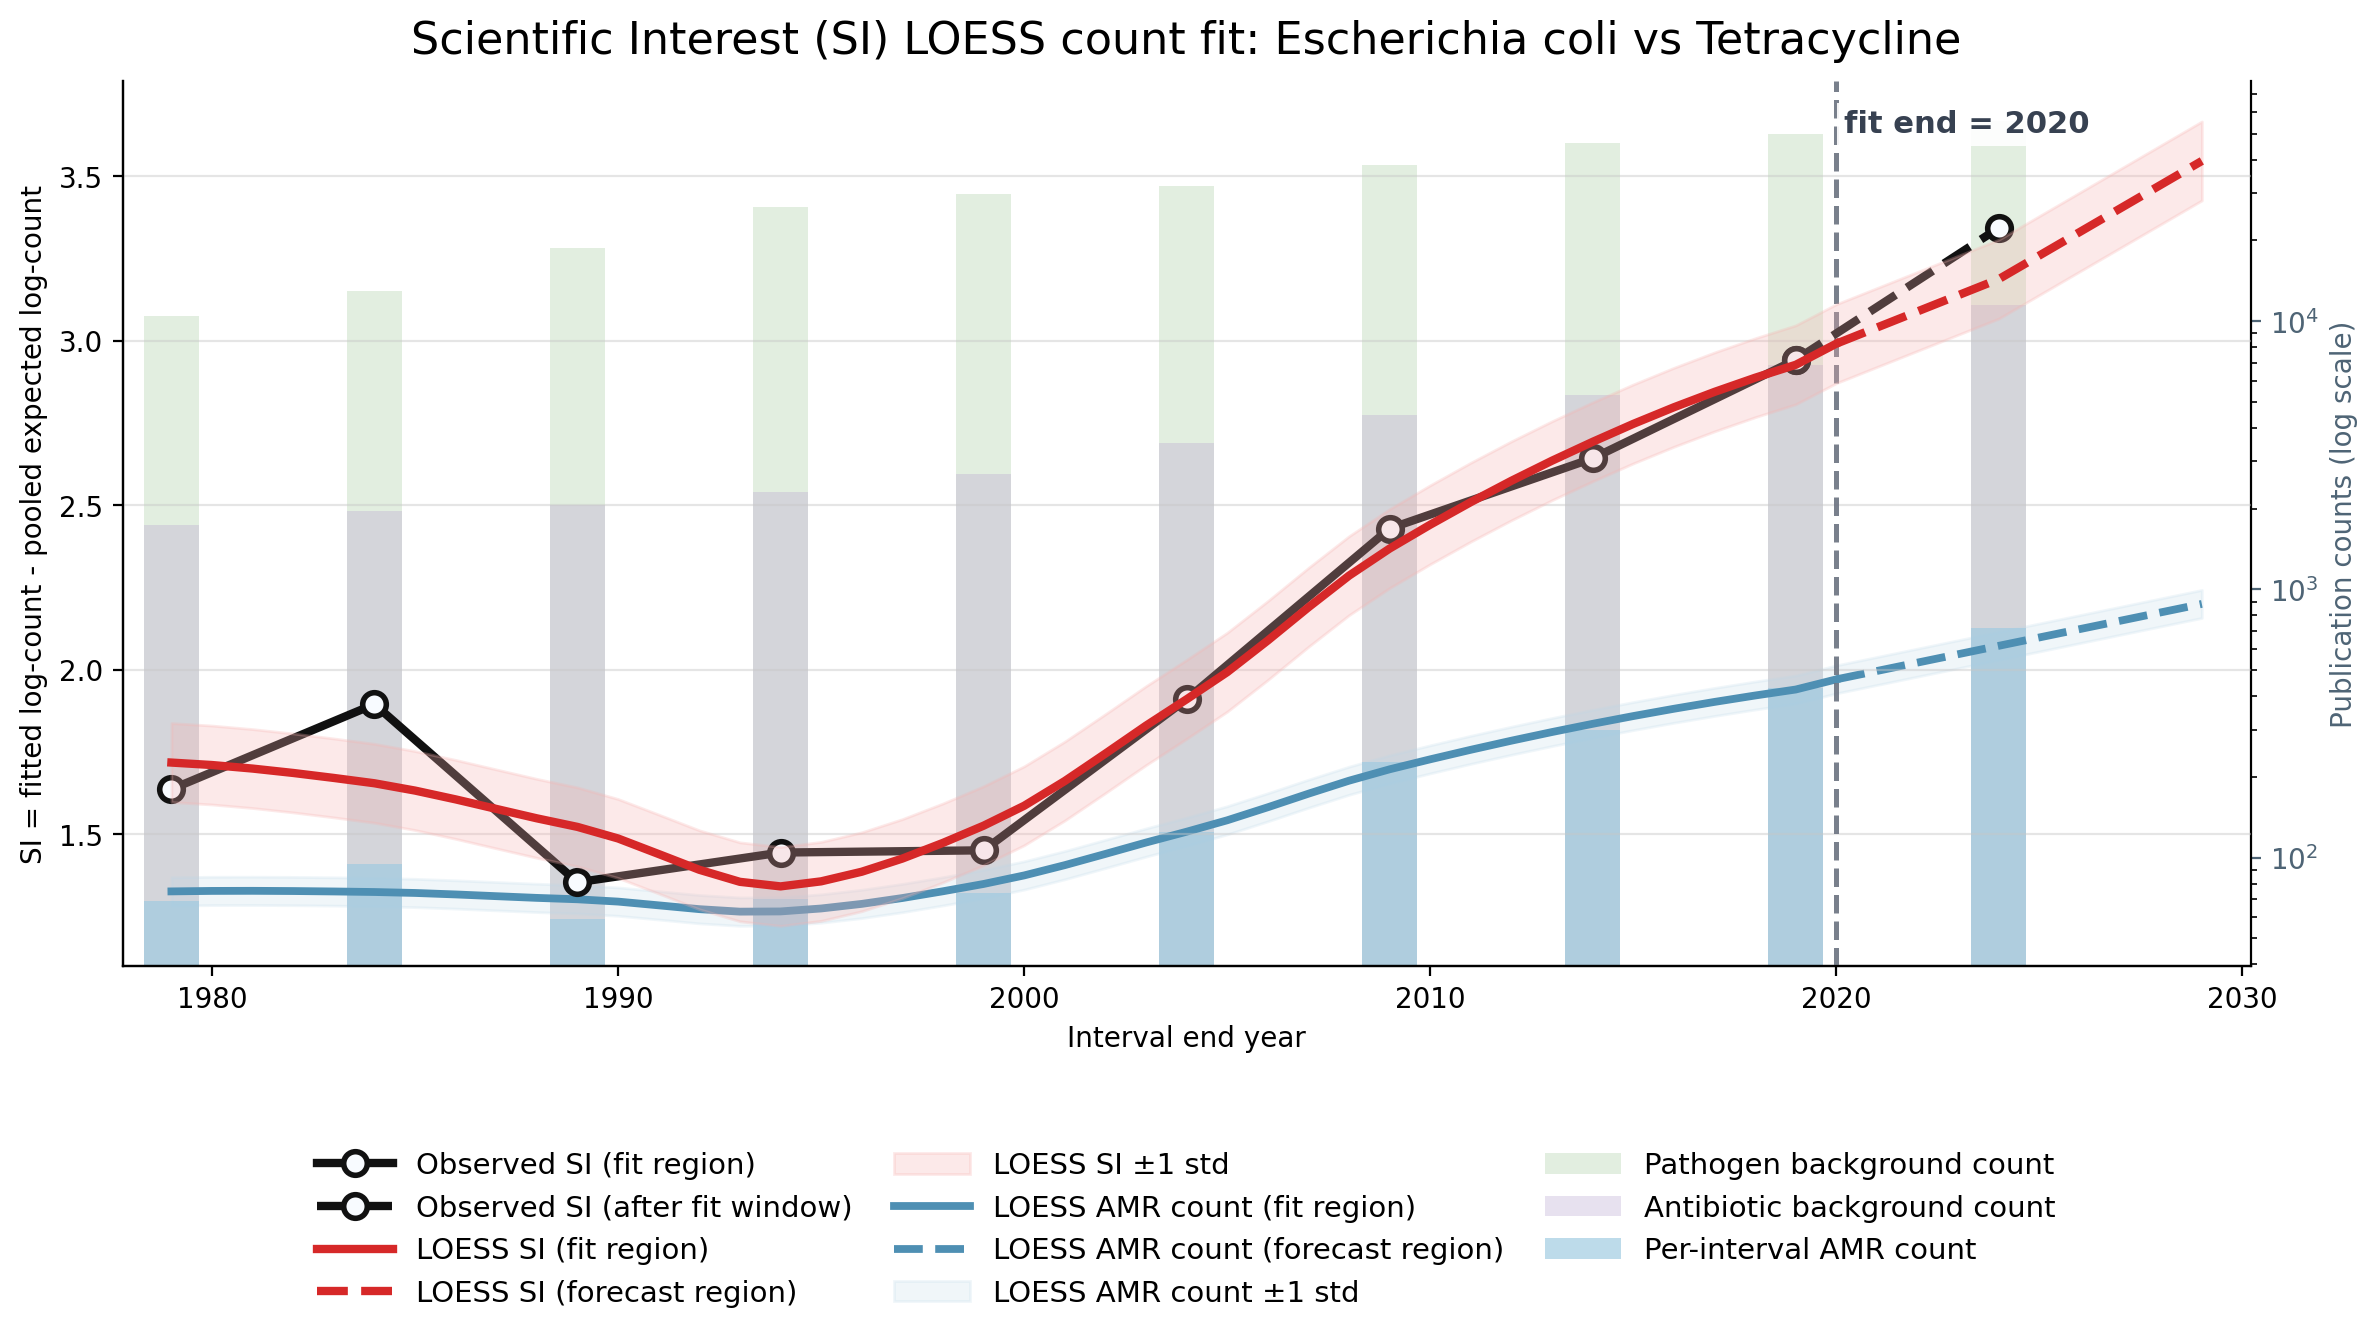

Plotting Enterococcus faecalis vs Vancomycin


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'Chernobyl! trL>n 7'). Falling back to linear LOESS.
  warnings.warn(


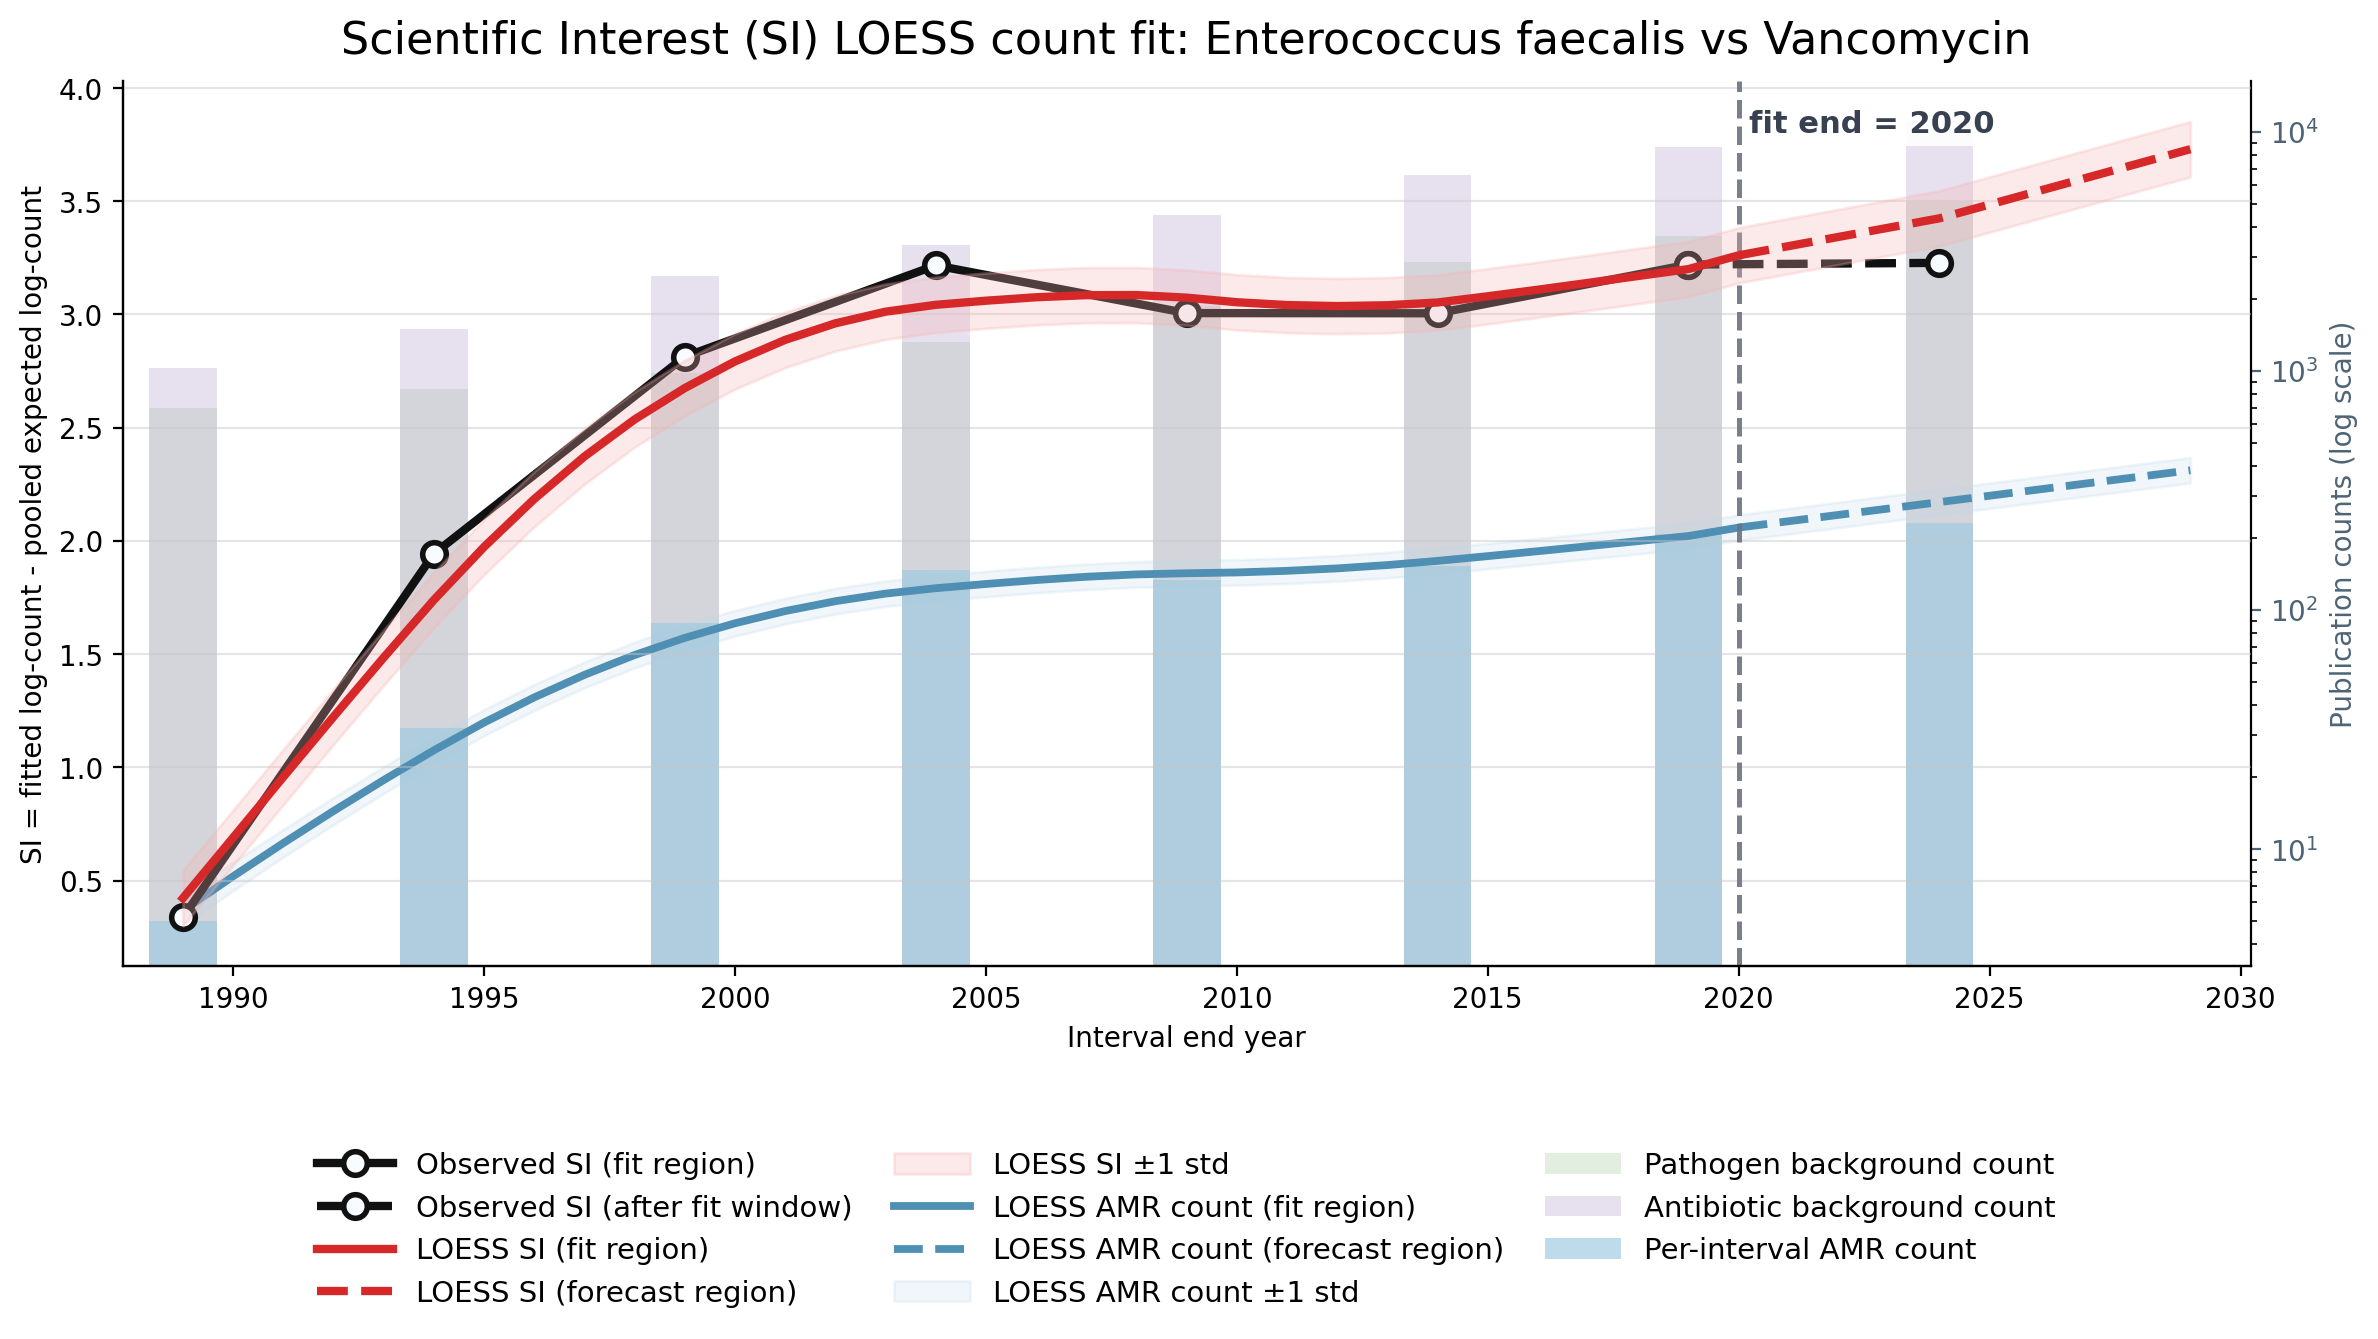

Plotting Acinetobacter baumannii vs Colistin


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:215: RuntimeWarning: Quadratic LOESS was numerically unstable (b'There are other near singularities as well. 25.502'). Falling back to linear LOESS.
  warnings.warn(
/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/amr/scientific_interest.py:227: RuntimeWarning: Linear LOESS was numerically unstable (b'There are other near singularities as well. 25.502'). Falling back to quadratic polynomial fit.
  warnings.warn(


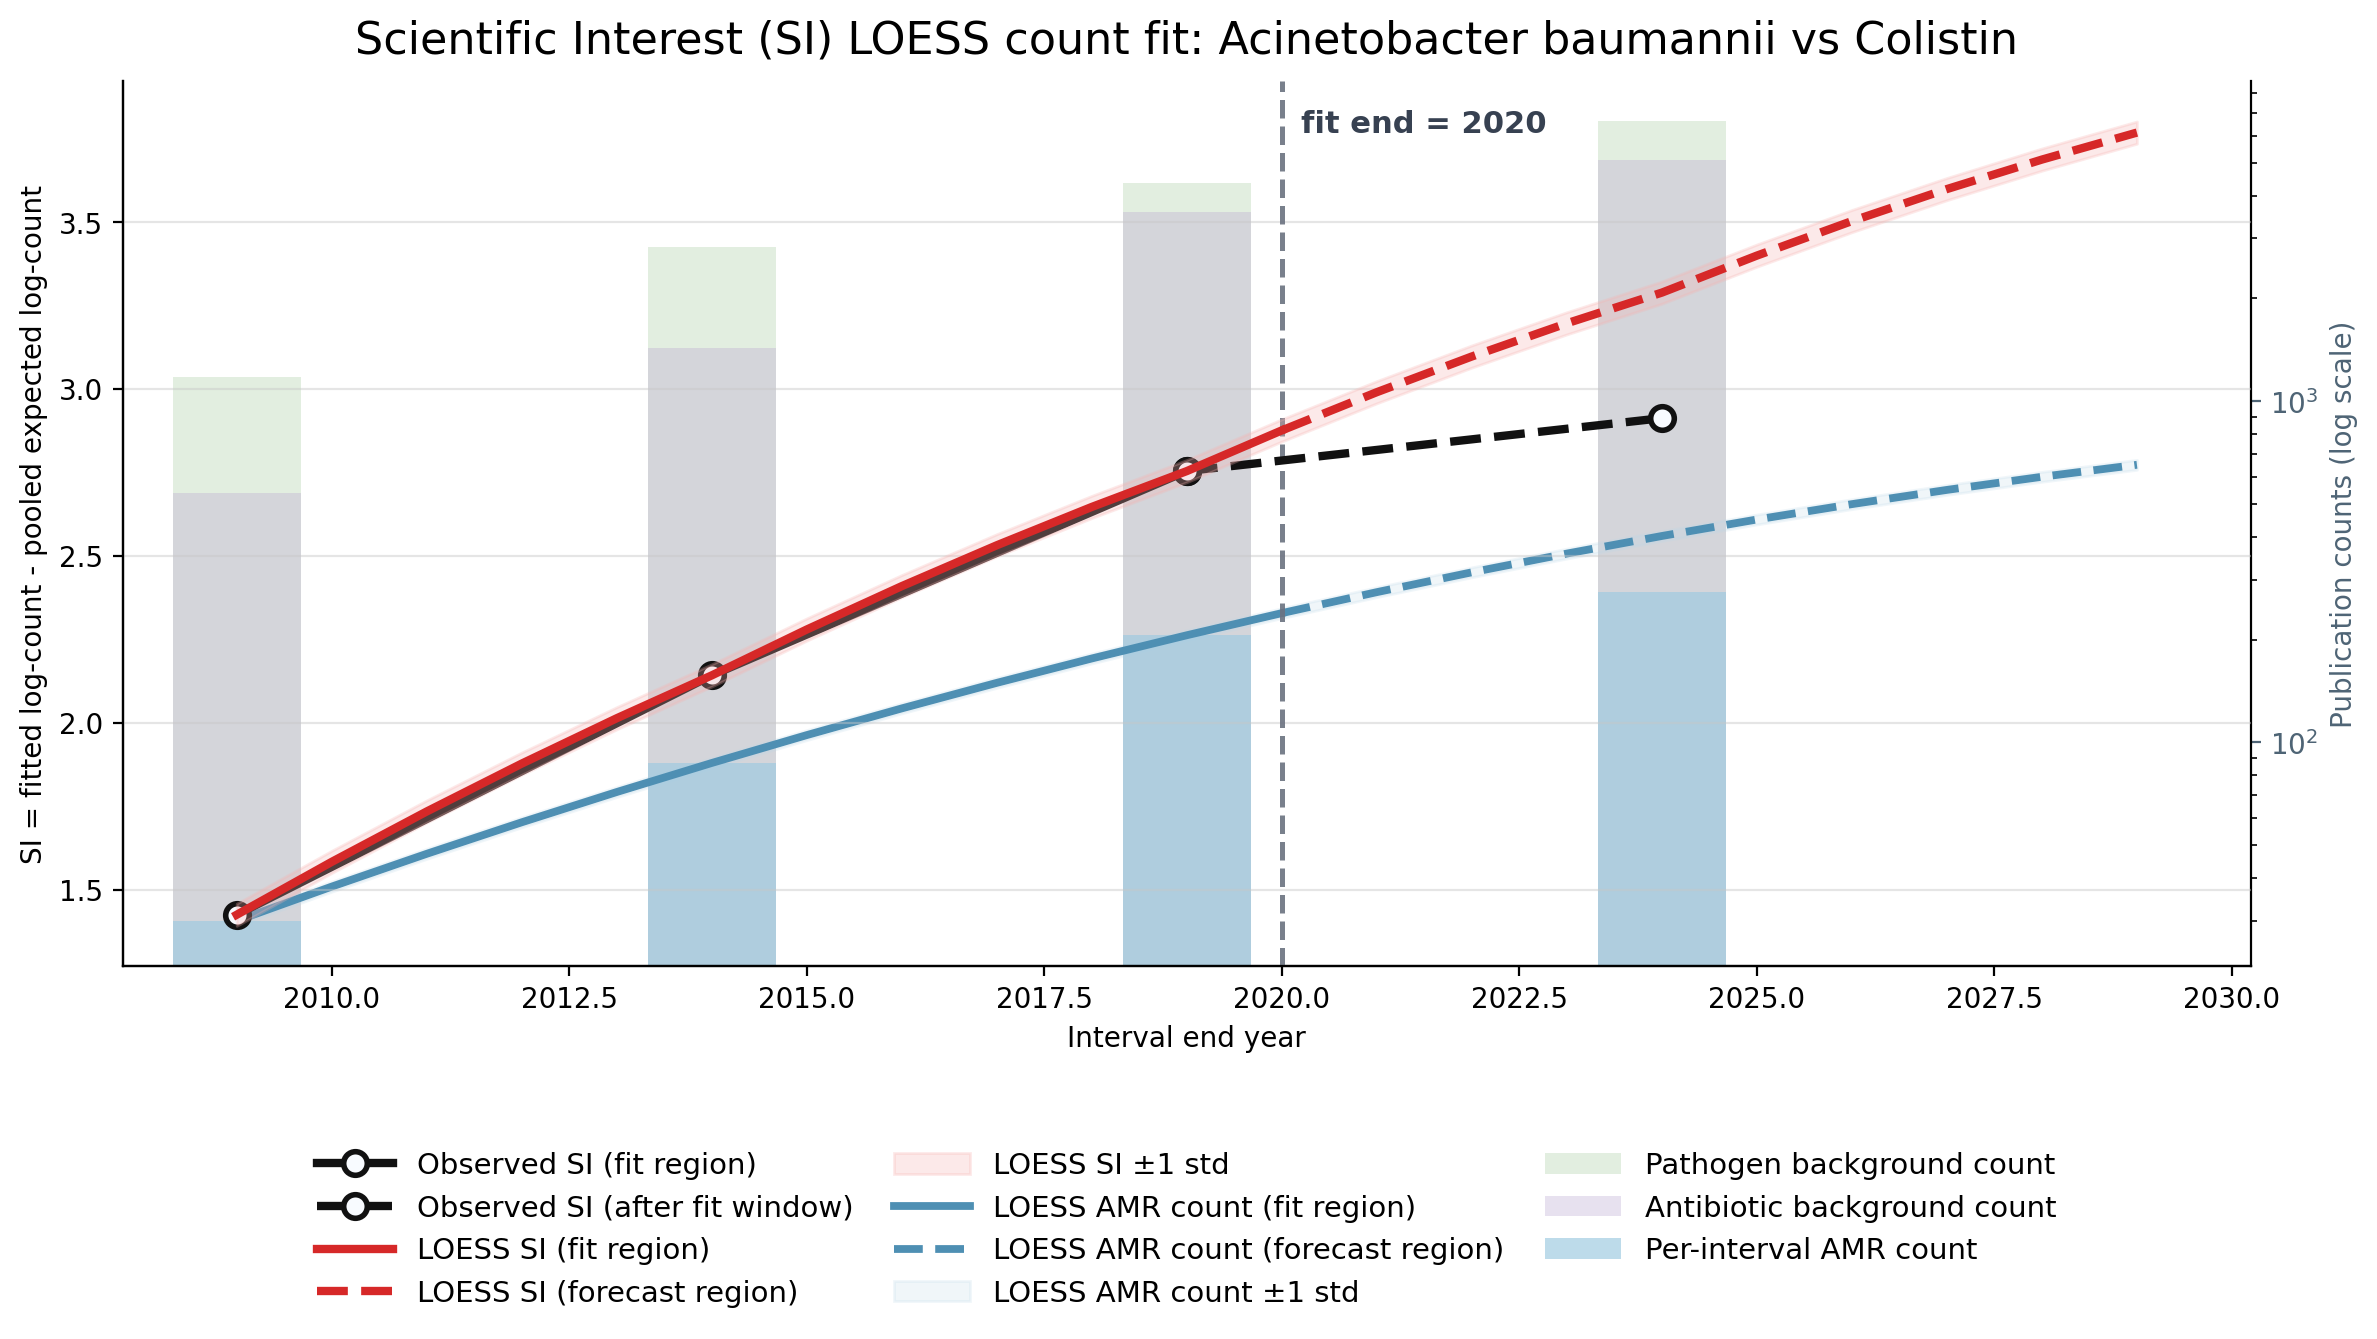

Plotting Staphylococcus aureus vs Oxacillin


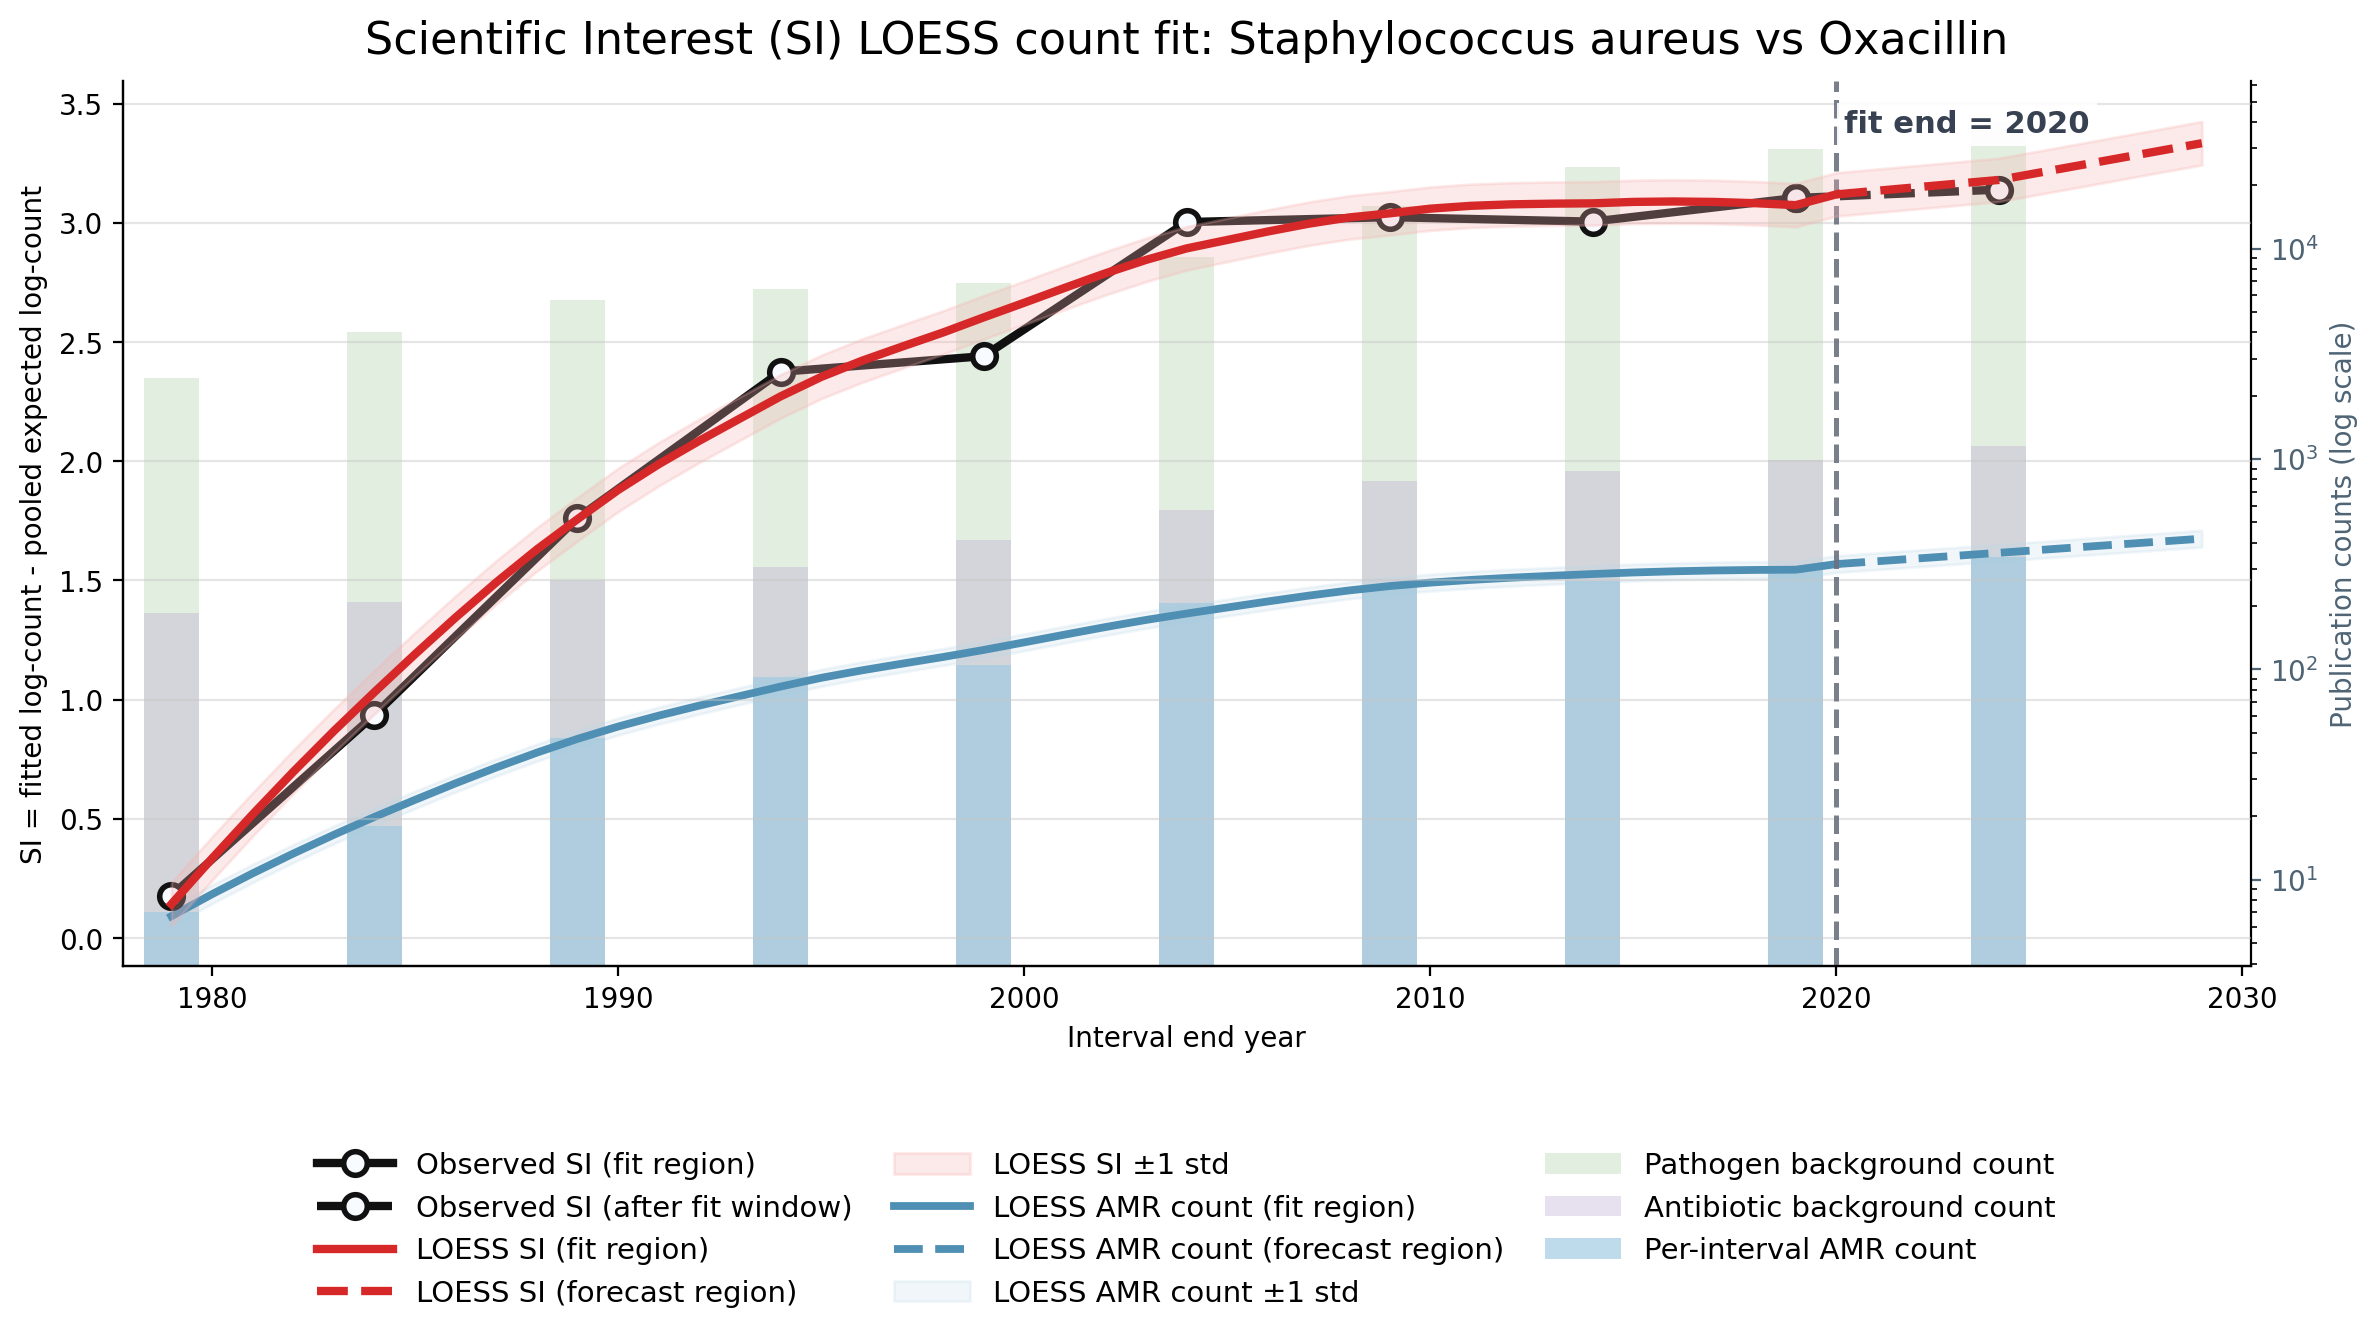

Plotting Staphylococcus aureus vs Erythromycin


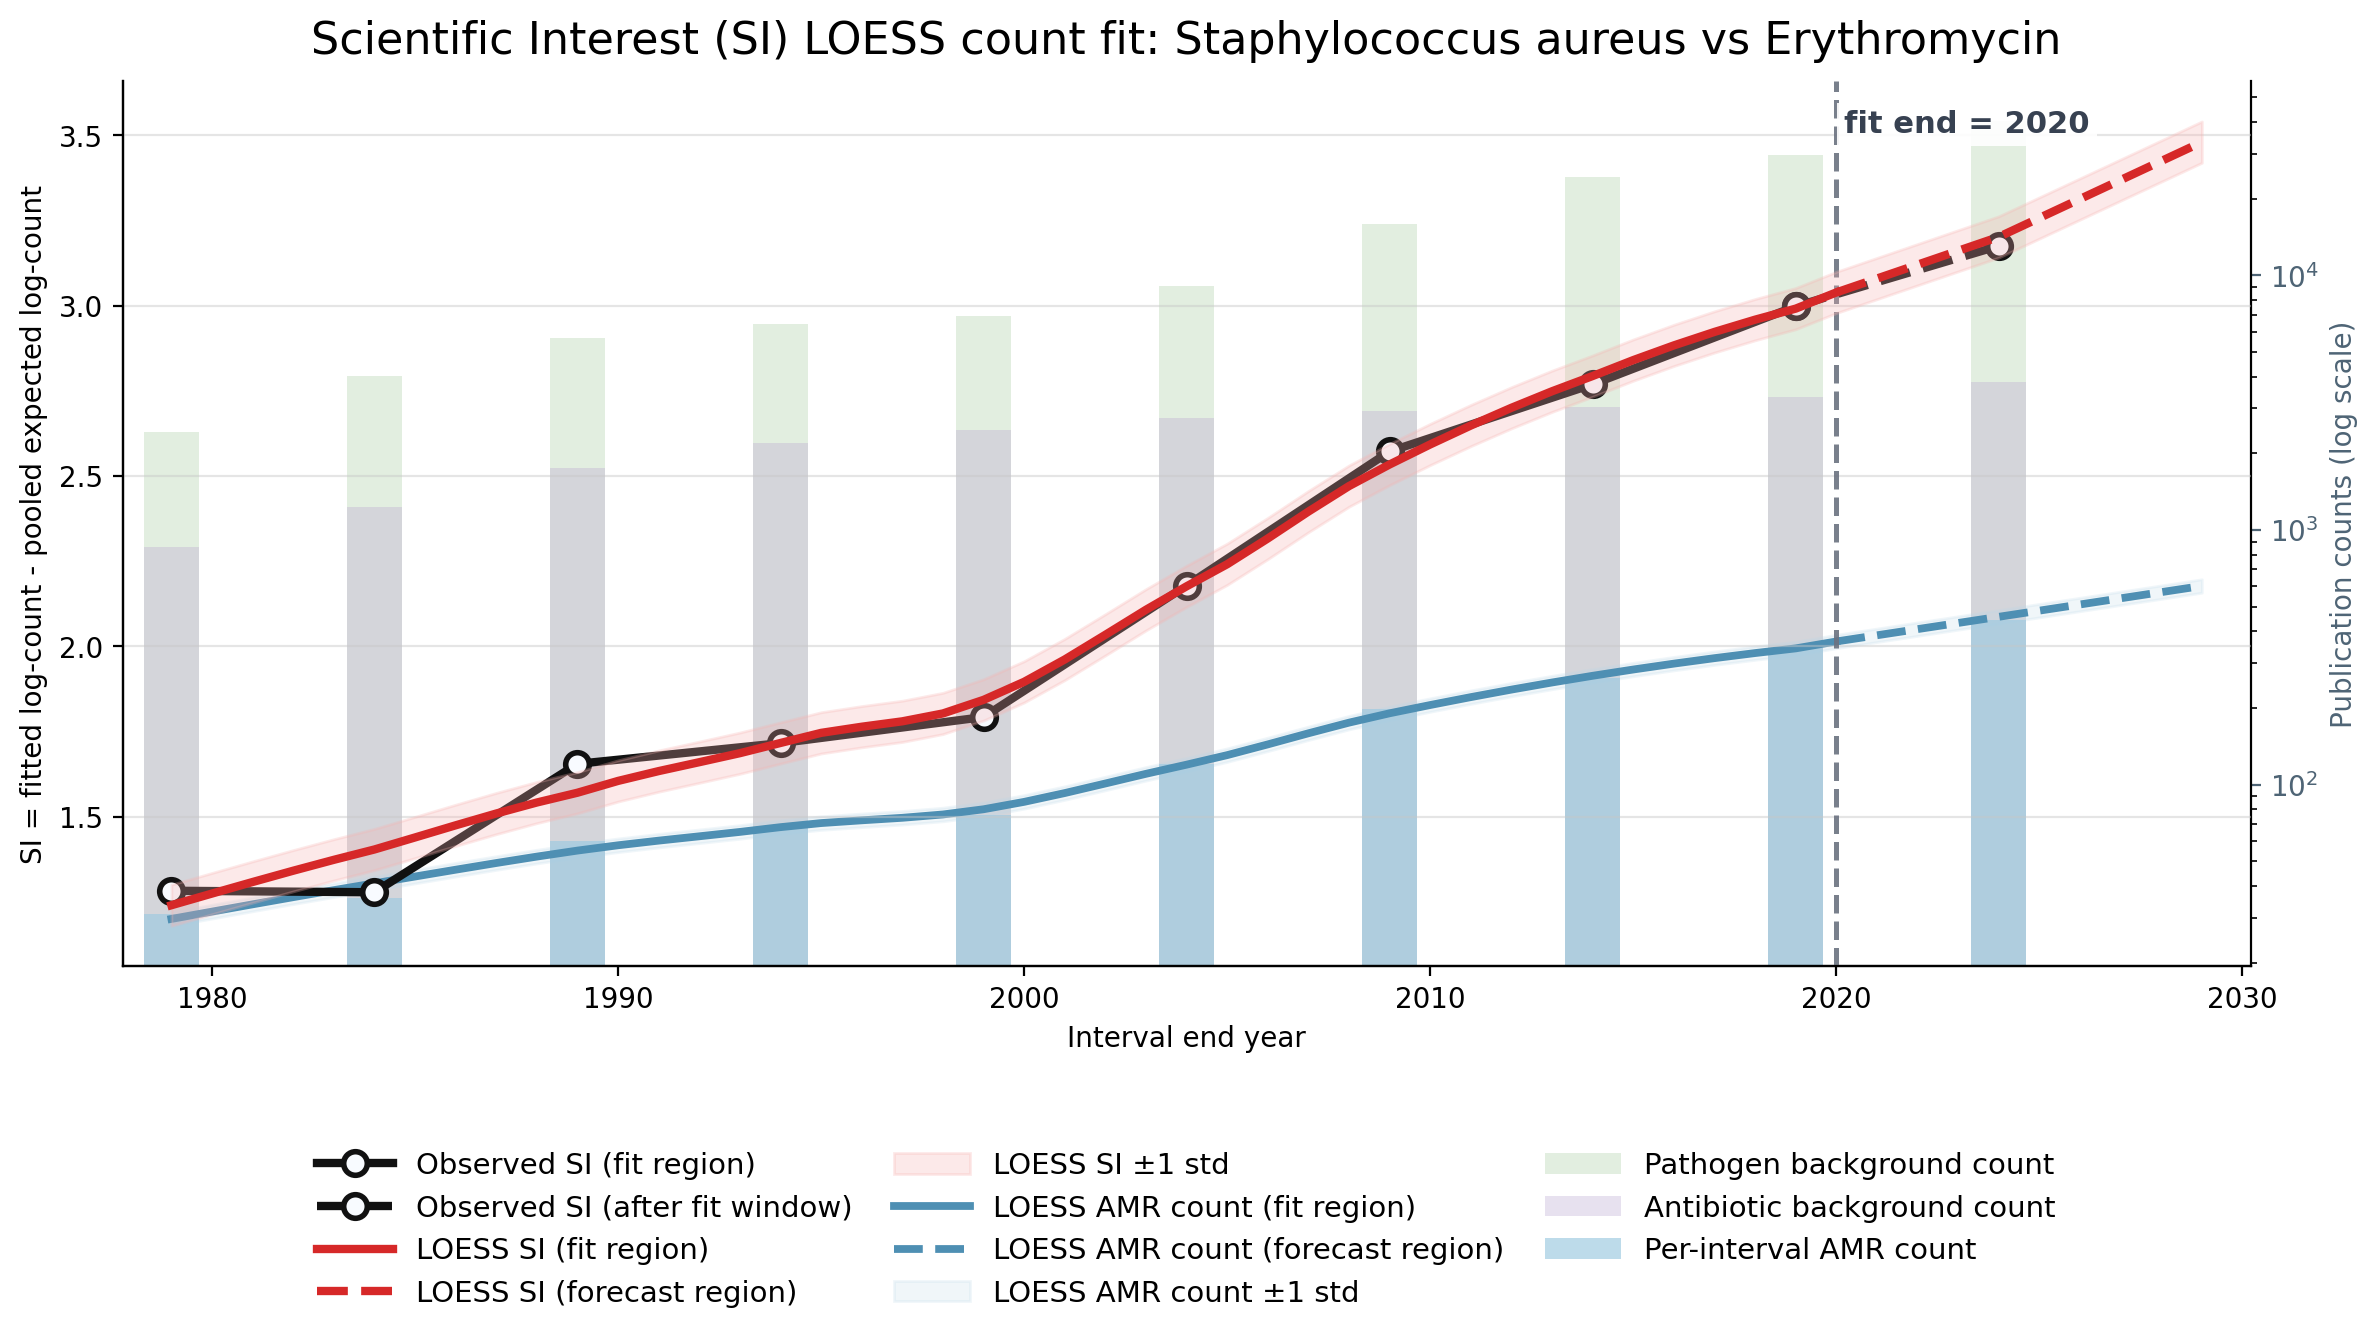

Plotting Escherichia coli vs Trimethoprim


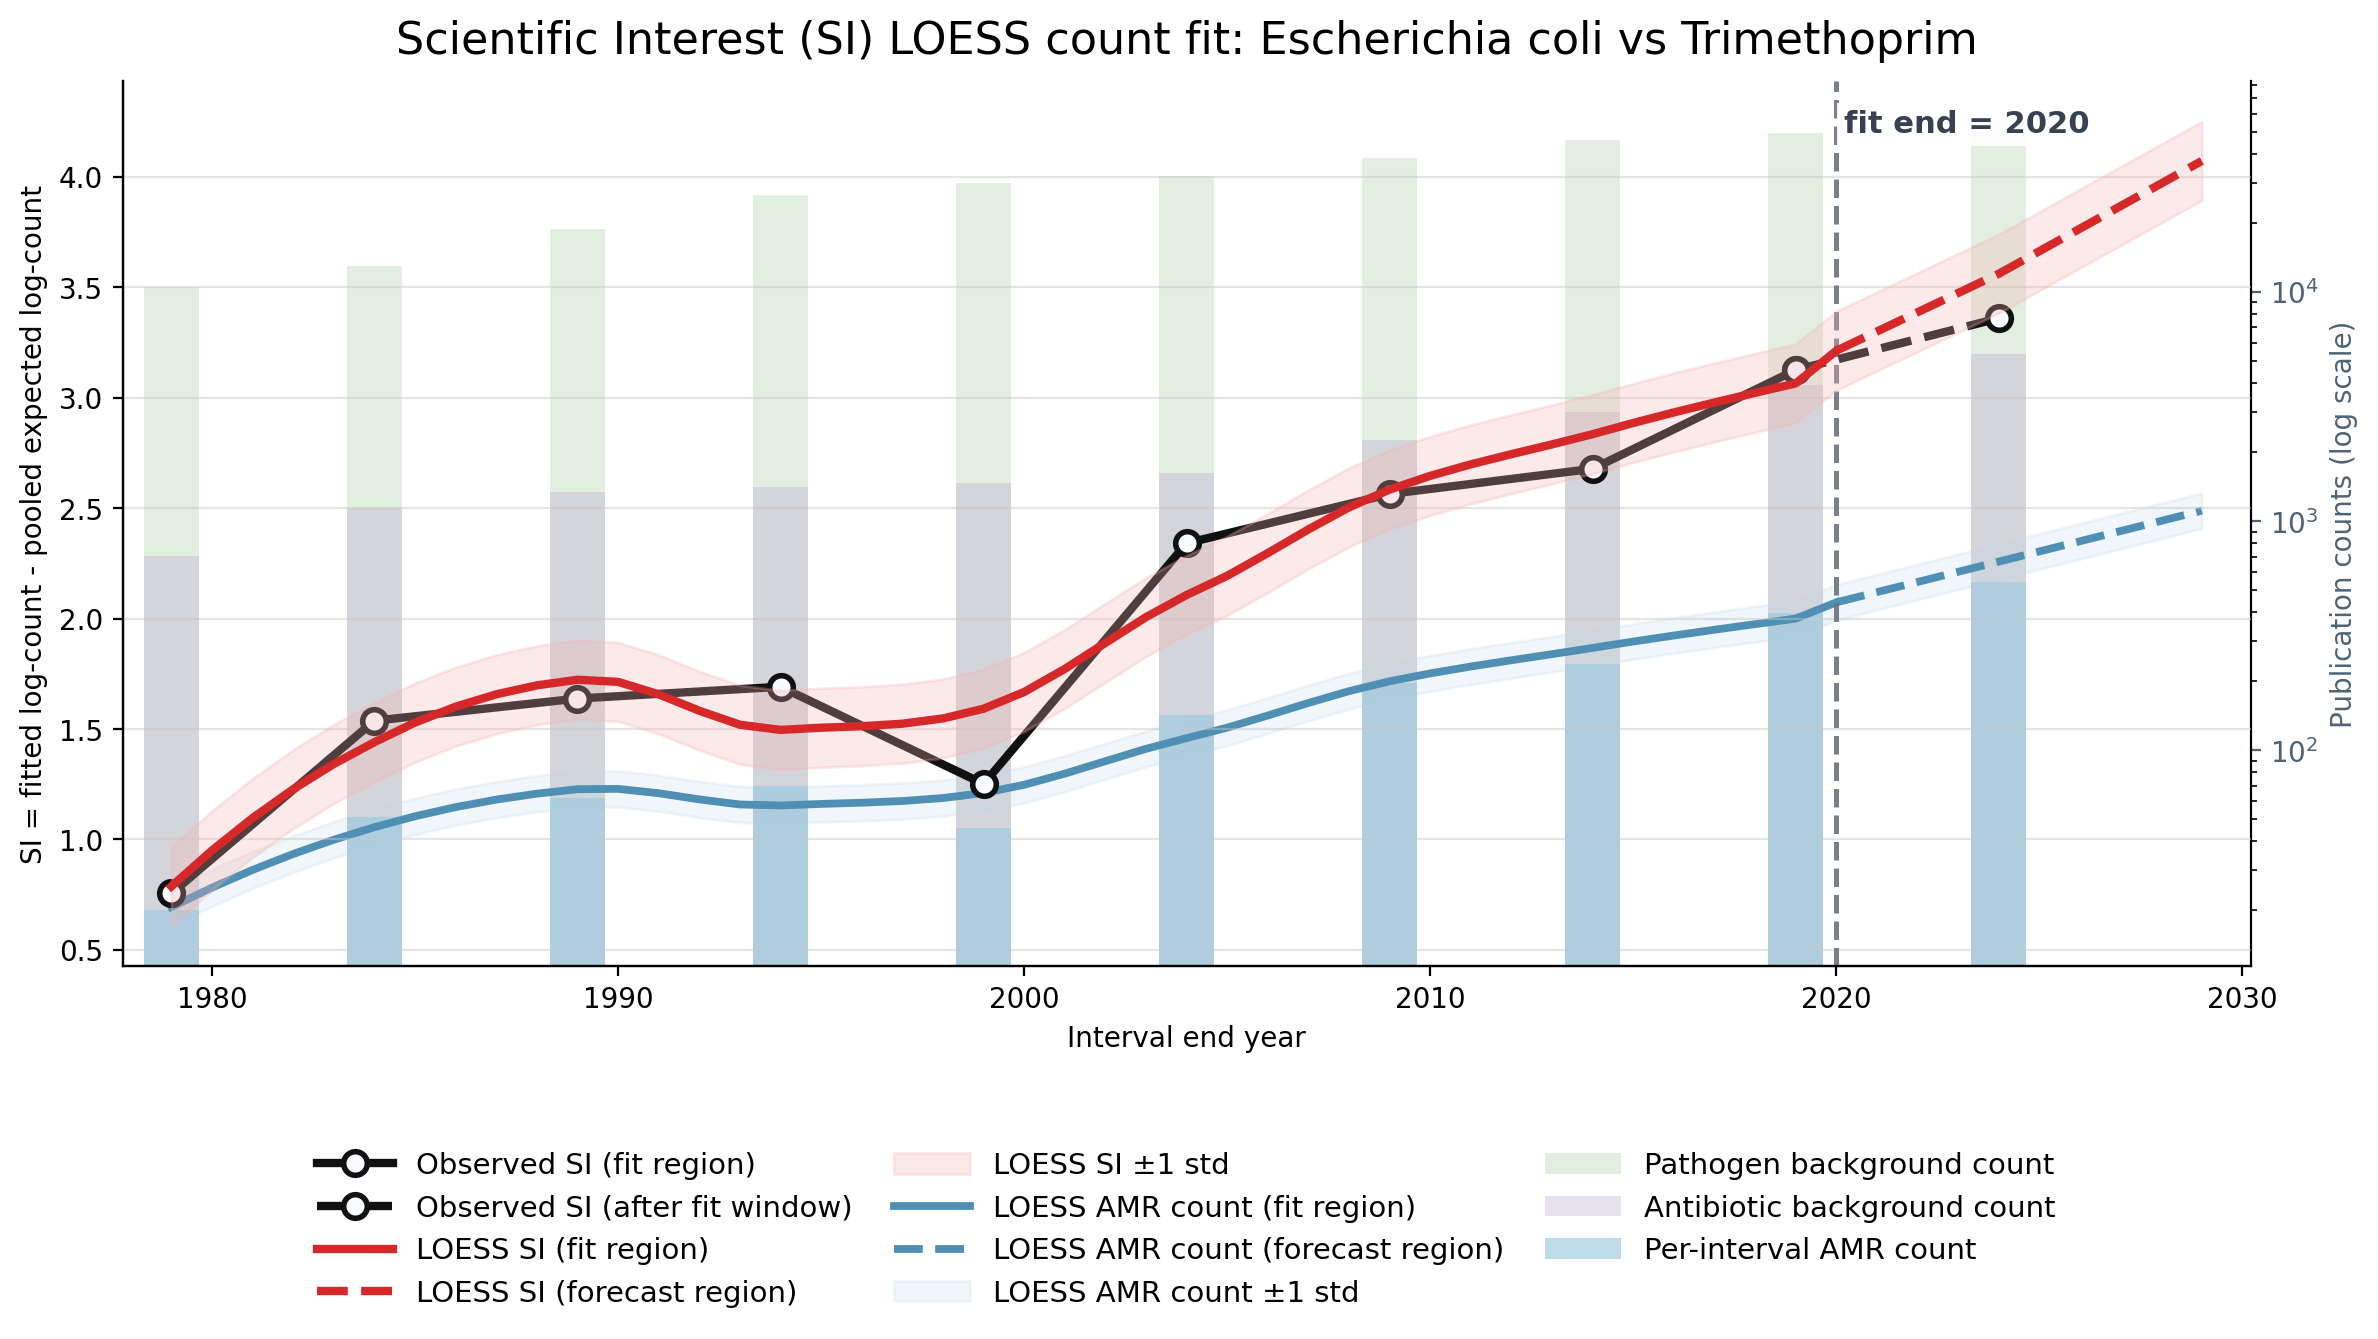

Plotting Staphylococcus aureus vs Vancomycin


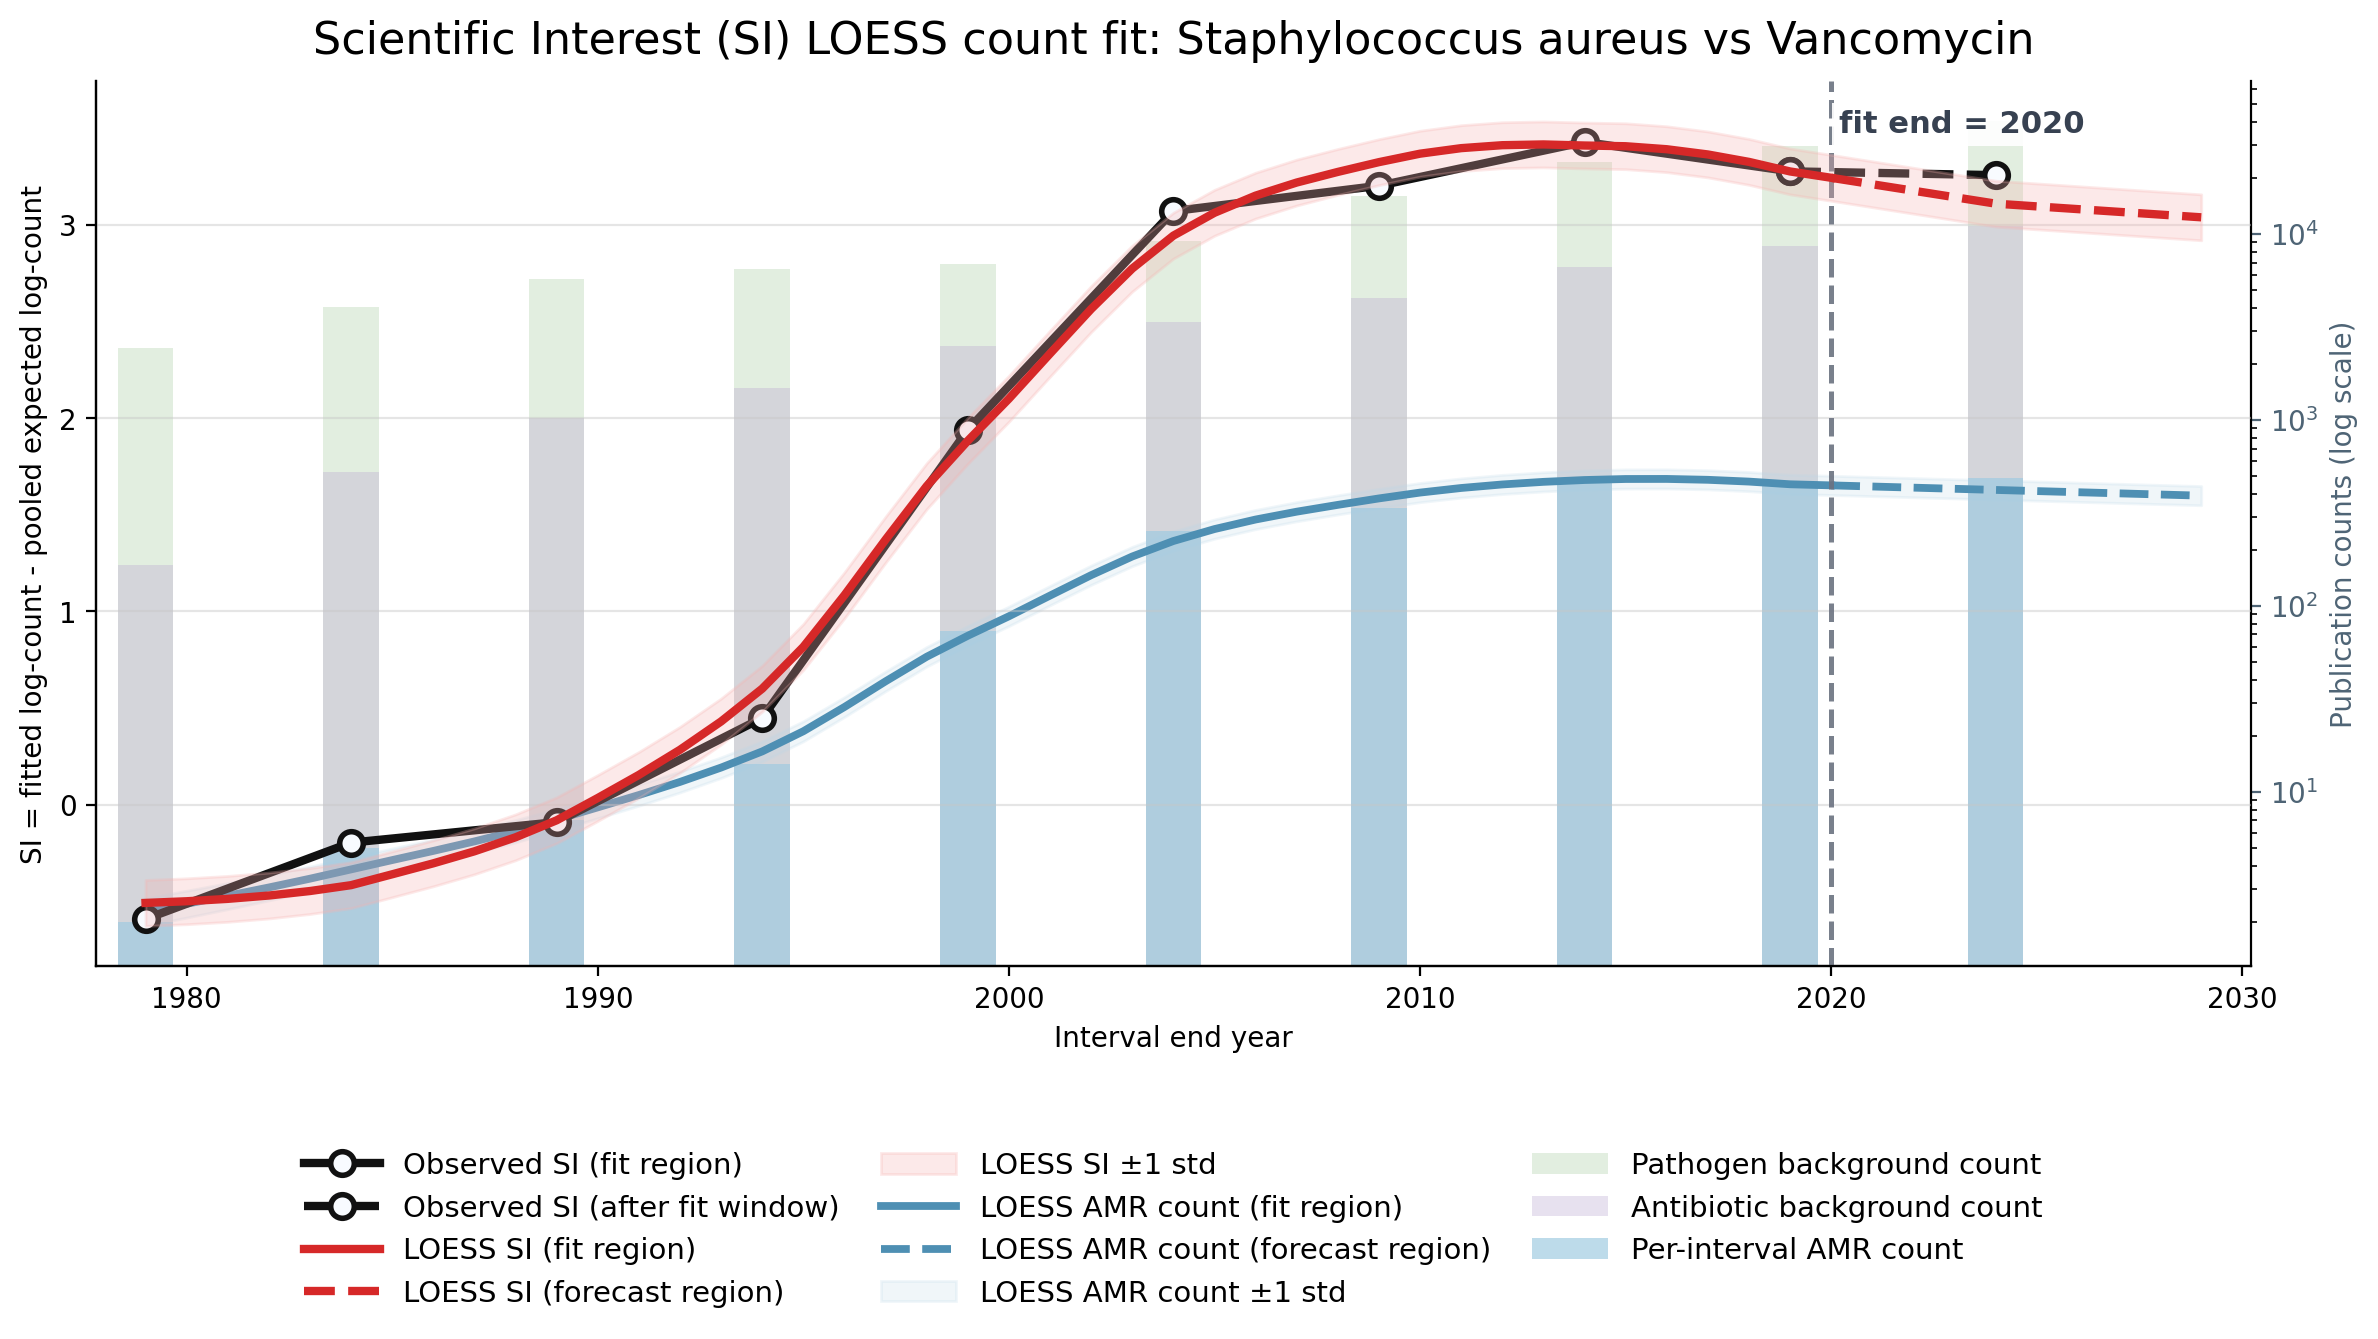

Saved 13 plot PNGs to pareto_pngs


In [15]:
# Example:
n_pareto_shells = 4
pareto_df = display_si_amr_pareto_front(si_df, n_pareto_shells=n_pareto_shells)
pareto_plot_results = plot_si_prediction_for_pareto_pairs(
    si_df,
    pareto_df,
    fit_start_year=1970,
    fit_end_year=2020,
    num_additional_years=5,
    loess_frac=0.7,
    loess_degree=2,
    n_pareto_shells=n_pareto_shells,
    save_dir="pareto_pngs",
)
